<div dir="rtl" align="right">

# تحلیل داده‌های فروش و رفتار مشتریان Olist

این نوتبوک کل پروژه را در یک فایل جمع می‌کند: شناخت داده خام، پاک‌سازی، شش محور تحلیل
کسب‌وکاری، تحلیل‌های ترکیبی و جمع‌بندی برای مدیریت. همه جدول‌ها و نمودارها با کد همین
فایل ساخته می‌شوند و هیچ نتیجه‌ای از پیش ذخیره نشده است.

**تهیه‌کنندگان**

| نقش | نام |
| --- | --- |
| تحلیل‌گر داده و نویسنده گزارش | آرش علیدادی |
| تحلیل‌گر داده | «نام همگروه دوم» |
| تحلیل‌گر داده | «نام همگروه سوم» |

**نحوه اجرا**

۱. فایل‌های CSV را در مسیر `data/raw` قرار دهید.
۲. بسته‌های `requirements.txt` را نصب کنید: `pip install -r requirements.txt`
۳. از منوی Kernel گزینه Restart & Run All را بزنید.

مسیر داده به‌صورت نسبی پیدا می‌شود، بنابراین پوشه پروژه را می‌توانید هر جای دیگری هم
اجرا کنید. اگر فونت فارسی در `assets/fonts` نباشد، نمودارها با فونت فارسی سیستم رسم
می‌شوند و اجرا متوقف نمی‌شود.

</div>

In [1]:
# --- ابزارها و تنظیمات مشترک ---
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
import seaborn as sns
from IPython.display import HTML, display

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
# سقف نمایش بالا برده می‌شود تا هیچ ستون یا سطری با «...» پنهان نشود، اما
# مقدارها نامحدود (۱-‎) نیستند تا خروجی نوتبوک قابل استفاده بماند.
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 100)

plt.rcParams.update({
    "figure.figsize": (10.5, 4.8),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.unicode_minus": False,
    "font.size": 10,
})

CORE_START, CORE_END = "2017-01", "2018-08"
COLOR_MAIN, COLOR_ACCENT, COLOR_MUTED = "#2E5F8A", "#C0392B", "#95A5A6"


def persian_font():
    '''فونت فارسی را از assets برمی‌دارد و در نبود آن به فونت سیستم برمی‌گردد.'''
    for path in (Path("assets/fonts/Vazirmatn-Regular.ttf"),
                 Path("../assets/fonts/Vazirmatn-Regular.ttf")):
        if path.exists():
            font_manager.fontManager.addfont(str(path))
            return font_manager.FontProperties(fname=str(path)).get_name()
    installed = {item.name for item in font_manager.fontManager.ttflist}
    for name in ("Vazirmatn", "Vazir", "Tahoma", "Segoe UI", "Arial",
                 "Noto Naskh Arabic", "DejaVu Sans"):
        if name in installed:
            return name
    return "DejaVu Sans"


plt.rcParams["font.family"] = persian_font()


# --- متن فارسی: یک تابع مشترک برای همه نمودارها و جدول‌ها ---------------
import arabic_reshaper
from bidi.algorithm import get_display


def fa(text):
    '''متن فارسی را برای یک نمایشگر چپ‌به‌راست قابل‌نمایش می‌کند.

    دو کار و به همین ترتیب: ``arabic_reshaper`` حروف را به شکل چسبیده تبدیل
    می‌کند و ``get_display`` ترتیب را از راست‌به‌چپ به چپ‌به‌راست می‌گرداند.
    پردازش خط‌به‌خط است تا خطوط یک متن چندخطی هرگز جابه‌جا نشوند.

    چرا نسخه‌ای که هر بخش فارسی را جدا می‌کند و با ``[::-1]`` معکوس می‌کند اینجا
    به کار نرفته است: آن روش ترتیب کلمات را در جمله‌های ترکیبی فارسی/انگلیسی
    خراب می‌کند (نمونه: «رشد سفارش‌ها در Black Friday سال 2018»). الگوریتم استاندارد
    bidi که ``get_display`` پیاده کرده، همین کار را درست انجام می‌دهد.
    '''
    text = str(text)
    lines = []
    for line in text.split("\n"):
        lines.append(get_display(arabic_reshaper.reshape(line)) if line.strip() else line)
    return "\n".join(lines)


def renderer_shapes_persian():
    '''آیا Matplotlib نصب‌شده خودش حروف را می‌چسباند و ترتیب را اصلاح می‌کند؟'''
    try:
        import matplotlib as mpl
        from matplotlib import ft2font

        if not getattr(ft2font, "__libraqm_version__", ""):
            return False
        major, minor = (int(part) for part in mpl.__version__.split(".")[:2])
        return (major, minor) >= (3, 11)
    except Exception:
        return False


HANDLES_BIDI = renderer_shapes_persian()


def rtl(text):
    '''متن آمادهٔ رسم در Matplotlib.

    اگر نسخهٔ نصب‌شده Raqm داشته باشد (اینجا Matplotlib 3.11)، خود موتور رسم شکل
    حروف و ترتیب را اعمال می‌کند و متن خام باید دست‌نخورده بماند؛ دادن متن
    معکوس‌شده به آن کلمات را برعکس نشان می‌دهد. روی نسخه‌های قدیمی‌تر که Raqm
    ندارند همین تابع fa را صدا می‌زند تا خروجی درست بماند.
    '''
    return str(text) if HANDLES_BIDI else fa(text)


def apply_rtl(fig):
    '''rtl() را روی همهٔ متن‌های یک نمودار اعمال می‌کند.

    عنوان، برچسب محورها، تیک‌ها، راهنما، annotationها و متن‌های داخل نمودار
    پوشش داده می‌شوند؛ بنابراین هیچ متنی از قلم نمی‌افتد و همه از یک مسیر
    می‌گذرند.
    '''
    for axis in fig.axes:
        for artist in (axis.title, getattr(axis, "_left_title", None),
                       getattr(axis, "_right_title", None),
                       axis.xaxis.label, axis.yaxis.label):
            if artist is not None and artist.get_text():
                artist.set_text(rtl(artist.get_text()))
        for tick_axis in (axis.xaxis, axis.yaxis):
            for tick in tick_axis.get_major_ticks():
                if tick.label1.get_text():
                    tick.label1.set_text(rtl(tick.label1.get_text()))
        legend = axis.get_legend()
        if legend is not None:
            for entry in legend.get_texts():
                entry.set_text(rtl(entry.get_text()))
        for child in axis.texts:
            if child.get_text():
                child.set_text(rtl(child.get_text()))
    return fig


_show = plt.show


def _show_with_rtl(*args, **kwargs):
    '''نمودار را بعد از عبور دادن همهٔ متن‌ها از rtl() نمایش می‌دهد.'''
    apply_rtl(plt.gcf())
    return _show(*args, **kwargs)


plt.show = _show_with_rtl

# جدول‌های pandas هم راست‌به‌چپ و راست‌چین نمایش داده شوند
# (CSS فقط جهت و چیدمان را عوض می‌کند؛ پردازش متن کار fa/rtl است)
display(HTML(
    "<style>"
    ".dataframe { direction: rtl; }"
    ".dataframe th, .dataframe td { text-align: right !important; }"
    ".dataframe thead th { text-align: right !important; }"
    "</style>"
))


def raw_dir():
    '''پوشه داده خام را از پوشه جاری یا پوشه‌های والد پیدا می‌کند.'''
    for base in [Path.cwd(), *Path.cwd().resolve().parents]:
        if (base / "data" / "raw" / "olist_orders_dataset.csv").exists():
            return base / "data" / "raw"
    return Path("data/raw")


DATA_DIR = raw_dir()
print("پوشه داده:", DATA_DIR.resolve())


def barh(series, title, xlabel, fmt="{:,.0f}", color=COLOR_MAIN, figsize=(9.4, 4.8)):
    '''نمودار میله‌ای افقی از یک Series (index برچسب، مقدار عدد).'''
    fig, ax = plt.subplots(figsize=figsize)
    labels = [str(item).replace("_", " ") for item in series.index]
    values = series.to_numpy(dtype=float)
    ax.barh(labels[::-1], values[::-1], color=color)
    for row, value in enumerate(values[::-1]):
        ax.text(value, row, "  " + fmt.format(value), va="center", fontsize=9)
    ax.set_title(rtl(title), loc="right", fontsize=12)
    ax.set_xlabel(rtl(xlabel))
    ax.margins(x=0.16)
    fig.tight_layout()
    plt.show()


def bars(series, title, ylabel, fmt="{:,.0f}", color=COLOR_MAIN,
         figsize=(9.8, 4.6), rotate=0):
    '''نمودار میله‌ای عمودی از یک Series با برچسب مقدار روی هر میله.'''
    fig, ax = plt.subplots(figsize=figsize)
    labels = [str(item).replace("_", " ") for item in series.index]
    values = series.to_numpy(dtype=float)
    ax.bar(labels, values, color=color)
    for column, value in enumerate(values):
        ax.text(column, value, fmt.format(value), ha="center", va="bottom", fontsize=9)
    ax.set_title(rtl(title), loc="right", fontsize=12)
    ax.set_ylabel(rtl(ylabel))
    ax.margins(y=0.15)
    if rotate:
        ax.tick_params(axis="x", rotation=rotate)
    fig.tight_layout()
    plt.show()

پوشه داده: /workspace/chats/86635db235004c1b8518383d/data/raw


<div dir="rtl" align="right">

### آزمون نمایش متن فارسی

پیش از هر تحلیلی، درستی نمایش متن بررسی می‌شود. تابع `fa` متن را برای نمایشگر
چپ‌به‌راست آماده می‌کند و `rtl` همان متن را به شکلی می‌دهد که Matplotlib این محیط
می‌خواهد. خروجی `fa` در کنسول معکوس دیده می‌شود؛ این طبیعی است، چون در کنسول چپ‌به‌راست
چاپ می‌شود. مهم این است که متن داخل نمودار درست خوانده شود.

</div>

Matplotlib 3.11.2 | پردازش خودکار bidi: True
ورودی: رشد سفارش‌ها در Black Friday سال 2018
fa() : 2018 ﻝﺎﺳ Black Friday ﺭﺩ ﺎﻫﺵﺭﺎﻔﺳ ﺪﺷﺭ ← خروجی برای نمایشگر چپ‌به‌راست
rtl(): رشد سفارش‌ها در Black Friday سال 2018 ← آن‌چه به Matplotlib می‌رسد

ورودی: میانگین فروش برابر با 1200 BRL
fa() : BRL 1200 ﺎﺑ ﺮﺑﺍﺮﺑ ﺵﻭﺮﻓ ﻦﯿﮕﻧﺎﯿﻣ ← خروجی برای نمایشگر چپ‌به‌راست
rtl(): میانگین فروش برابر با 1200 BRL ← آن‌چه به Matplotlib می‌رسد

ورودی: خط اول جمله است. ⏎ خط دوم جمله است.
fa() : .ﺖﺳﺍ ﻪﻠﻤﺟ ﻝﻭﺍ ﻂﺧ ⏎ .ﺖﺳﺍ ﻪﻠﻤﺟ ﻡﻭﺩ ﻂﺧ ← خروجی برای نمایشگر چپ‌به‌راست
rtl(): خط اول جمله است. ⏎ خط دوم جمله است. ← آن‌چه به Matplotlib می‌رسد



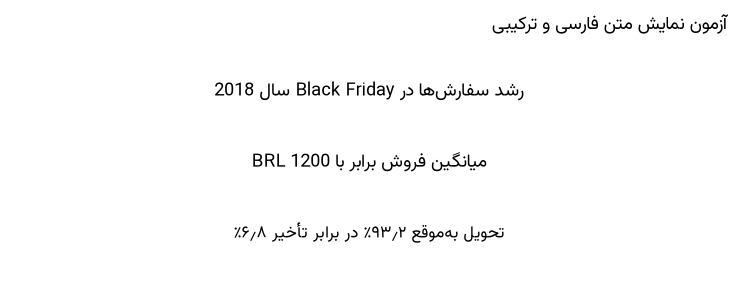

اگر سه خط داخل نمودار بالا درست خوانده می‌شوند، جهت و شکل متن درست است.


In [2]:
# --- آزمون fa / rtl با متن‌های فارسی، انگلیسی و ترکیبی ---
import matplotlib as mpl

print(f"Matplotlib {mpl.__version__} | پردازش خودکار bidi: {HANDLES_BIDI}")
samples = [
    "رشد سفارش‌ها در Black Friday سال 2018",
    "میانگین فروش برابر با 1200 BRL",
    "خط اول جمله است.\nخط دوم جمله است.",
]
for sample in samples:
    print("ورودی:", sample.replace("\n", " ⏎ "))
    print("fa() :", fa(sample).replace("\n", " ⏎ "), "← خروجی برای نمایشگر چپ‌به‌راست")
    print("rtl():", rtl(sample).replace("\n", " ⏎ "), "← آن‌چه به Matplotlib می‌رسد")
    print()

fig, ax = plt.subplots(figsize=(8.4, 2.8))
ax.axis("off")
ax.text(0.5, 0.78, rtl(samples[0]), ha="center", va="center", fontsize=12)
ax.text(0.5, 0.48, rtl(samples[1]), ha="center", va="center", fontsize=12)
ax.text(0.5, 0.18, rtl("تحویل به‌موقع ۹۳٫۲٪ در برابر تأخیر ۶٫۸٪"),
        ha="center", va="center", fontsize=11)
ax.set_title(rtl("آزمون نمایش متن فارسی و ترکیبی"), loc="right", fontsize=12)
plt.show()
print("اگر سه خط داخل نمودار بالا درست خوانده می‌شوند، جهت و شکل متن درست است.")

<div dir="rtl" align="right">

## بخش ۳ — شناخت داده‌ها

داده در نُه فایل CSV ذخیره شده است و هر فایل بخشی از فرایند خرید را توصیف می‌کند.
پیش از هر تحلیلی باید بدانیم هر جدول چه چیزی را ثبت می‌کند، هر سطر نماینده چیست و
با چه کلیدهایی می‌توان جدول‌ها را به هم وصل کرد.

</div>

In [3]:
# --- ۳.۱ بارگذاری فایل‌ها و شمارش سطر و ستون ---
FILES = {
    "orders": "olist_orders_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}
raw = {name: pd.read_csv(DATA_DIR / filename) for name, filename in FILES.items()}

inventory = pd.DataFrame([
    {"جدول": name, "فایل": FILES[name], "سطر": len(frame), "ستون": frame.shape[1]}
    for name, frame in raw.items()
])
display(inventory.set_index("جدول"))
print("مجموع سطرهای داده خام:", f"{sum(len(frame) for frame in raw.values()):,}")

,فایل,سطر,ستون
جدول,,,
orders,olist_orders_dataset.csv,99441,8
customers,olist_customers_dataset.csv,99441,5
order_items,olist_order_items_dataset.csv,112650,7
payments,olist_order_payments_dataset.csv,103886,5
reviews,olist_order_reviews_dataset.csv,99224,7
products,olist_products_dataset.csv,32951,9
sellers,olist_sellers_dataset.csv,3095,4
geolocation,olist_geolocation_dataset.csv,1000163,5
category_translation,product_category_name_translation.csv,71,2


مجموع سطرهای داده خام: 1,550,922


In [4]:
# --- ۳.۲ نوع داده ستون‌ها و مقادیر گمشده ---
dtypes = pd.concat({name: frame.dtypes.astype(str) for name, frame in raw.items()}, axis=1).fillna("-")
display(dtypes)

missing_rows = []
for name, frame in raw.items():
    share = frame.isna().mean().mul(100)
    for column in share[share > 0].index:
        missing_rows.append({
            "جدول": name,
            "ستون": column,
            "درصد گمشده": round(float(share[column]), 2),
            "تعداد": int(frame[column].isna().sum()),
        })
missing = pd.DataFrame(missing_rows).sort_values("درصد گمشده", ascending=False)
print("ستون‌های دارای مقدار گمشده:", len(missing))
display(missing.head(12).set_index("ستون"))

,orders,customers,order_items,payments,reviews,products,sellers,geolocation,category_translation
order_id,str,-,str,str,str,-,-,-,-
customer_id,str,str,-,-,-,-,-,-,-
order_status,str,-,-,-,-,-,-,-,-
order_purchase_timestamp,str,-,-,-,-,-,-,-,-
order_approved_at,str,-,-,-,-,-,-,-,-
order_delivered_carrier_date,str,-,-,-,-,-,-,-,-
order_delivered_customer_date,str,-,-,-,-,-,-,-,-
order_estimated_delivery_date,str,-,-,-,-,-,-,-,-
customer_unique_id,-,str,-,-,-,-,-,-,-
customer_zip_code_prefix,-,int64,-,-,-,-,-,-,-


ستون‌های دارای مقدار گمشده: 13


,جدول,درصد گمشده,تعداد
ستون,,,
review_comment_title,reviews,88.34,87656
review_comment_message,reviews,58.70,58247
order_delivered_customer_date,orders,2.98,2965
product_name_lenght,products,1.85,610
product_category_name,products,1.85,610
product_description_lenght,products,1.85,610
product_photos_qty,products,1.85,610
order_delivered_carrier_date,orders,1.79,1783
order_approved_at,orders,0.16,160


In [5]:
# --- ۳.۳ رکوردهای تکراری، یکتایی کلیدها و ارتباط جدول‌ها ---
duplicates = pd.DataFrame([
    {"جدول": name, "ردیف کاملاً تکراری": int(frame.duplicated().sum())}
    for name, frame in raw.items()
])
display(duplicates.set_index("جدول"))

key_checks = pd.DataFrame([
    {"جدول": "orders", "کلید": "order_id", "یکتاست؟": raw["orders"]["order_id"].is_unique},
    {"جدول": "customers", "کلید": "customer_id", "یکتاست؟": raw["customers"]["customer_id"].is_unique},
    {"جدول": "order_items", "کلید": "order_id + order_item_id",
     "یکتاست؟": not raw["order_items"].duplicated(["order_id", "order_item_id"]).any()},
    {"جدول": "reviews", "کلید": "review_id", "یکتاست؟": raw["reviews"]["review_id"].is_unique},
    {"جدول": "reviews", "کلید": "order_id", "یکتاست؟": raw["reviews"]["order_id"].is_unique},
])
display(key_checks.set_index("جدول"))

relations = [
    ("orders.customer_id به customers", "orders", "customer_id", "customers", "customer_id"),
    ("order_items.order_id به orders", "order_items", "order_id", "orders", "order_id"),
    ("order_items.product_id به products", "order_items", "product_id", "products", "product_id"),
    ("order_items.seller_id به sellers", "order_items", "seller_id", "sellers", "seller_id"),
    ("payments.order_id به orders", "payments", "order_id", "orders", "order_id"),
    ("reviews.order_id به orders", "reviews", "order_id", "orders", "order_id"),
]
orphans = pd.DataFrame([
    {"رابطه": label, "سطر بدون والد": int((~raw[child][column].isin(raw[parent][key])).sum())}
    for label, child, column, parent, key in relations
])
display(orphans.set_index("رابطه"))

print("شناسه نظر تکراری:", int(raw["reviews"]["review_id"].duplicated().sum()), "ردیف")
print("سفارش چند نظر دارد:", int(raw["reviews"]["order_id"].duplicated().sum()), "ردیف")

,ردیف کاملاً تکراری
جدول,
orders,0
customers,0
order_items,0
payments,0
reviews,0
products,0
sellers,0
geolocation,261831
category_translation,0


,کلید,یکتاست؟
جدول,,
orders,order_id,True
customers,customer_id,True
order_items,order_id + order_item_id,True
reviews,review_id,False
reviews,order_id,False


,سطر بدون والد
رابطه,
orders.customer_id به customers,0
order_items.order_id به orders,0
order_items.product_id به products,0
order_items.seller_id به sellers,0
payments.order_id به orders,0
reviews.order_id به orders,0


شناسه نظر تکراری: 814 ردیف
سفارش چند نظر دارد: 551 ردیف


<div dir="rtl" align="right">

**چه چیزی از این بخش فهمیدیم**

- جدول `orders` قلب داده است: هر سطر یک سفارش با وضعیت، زمان ثبت، زمان تحویل و تاریخ
  تخمینی تحویل. کلید اصلی آن `order_id` است.
- جدول‌های `order_items`، `payments` و `reviews` در سطح ریزتری از سفارش ثبت می‌شوند؛
  یک سفارش می‌تواند چند قلم، چند تراکنش پرداخت و در موارد نادر چند نظر داشته باشد.
  پس شمارش سطرهای این جدول‌ها با شمارش سفارش یکی نیست.
- `customers` به‌ازای هر سفارش یک شناسه دارد (`customer_id`) اما شخص واقعی با
  `customer_unique_id` شناخته می‌شود؛ بنابراین تعداد خریداران از تعداد ردیف‌های این
  جدول کمتر است.
- ستون‌های تاریخ به‌صورت متن خوانده شده‌اند و باید به `datetime` تبدیل شوند. مقادیر
  گمشده در جدول سفارش‌ها عمدتاً به سفارش‌های لغوشده یا در جریان مربوط است، نه به
  خطای ثبت داده.
- جدول `geolocation` صرفاً یک مرجع کد پستی است و برای تحلیل‌های این پروژه لازم نیست؛
  اطلاعات شهر و ایالت مشتری و فروشنده مستقیماً در جدول‌های خودشان هست.

نمودار ساختار جداول در سند پروژه آمده است؛ در ادامه فقط از جدول‌هایی استفاده می‌کنیم که
برای هر سؤال لازم است.

</div>

<div dir="rtl" align="right">

## بخش ۴ — پاک‌سازی و آماده‌سازی داده‌ها

تصمیم‌های پاک‌سازی را قبل از اجرا می‌نویسم تا بعداً قابل بازبینی باشد:

۱. **تاریخ‌ها**: پنج ستون تاریخ به `datetime` تبدیل می‌شوند. مقادیر نامعتبر به `NaT`
   می‌روند تا در محاسبات زمان تحویل وارد نشوند.
۲. **مقادیر گمشده**: ردیف‌ها حذف نمی‌شوند، چون هر سفارش بخشی از تصویر کسب‌وکار است.
   در عوض برای هر تحلیل، فقط سفارش‌هایی که ستون‌های لازم را دارند استفاده می‌شوند و
   تعداد نمونه همیشه گزارش می‌شود.
۳. **نظرات تکراری**: برای هر سفارش آخرین نظر ثبت‌شده نگه داشته می‌شود تا میانگین امتیاز
   یک سفارش را چند بار نشمارد.
۴. **دسته‌بندی محصول**: نام‌های پرتغالی با جدول ترجمه به انگلیسی برگردانده می‌شوند و
   محصولات بدون دسته‌بندی با برچسب `unknown` جدا می‌مانند.
۵. **ویژگی‌های جدید**: سال، ماه، روز هفته، مدت تحویل، روزهای تأخیر، طبقه تحویل و بازه
   شدت تأخیر ساخته می‌شوند. تأخیر بر پایه تاریخ (بدون ساعت) محاسبه می‌شود، چون تاریخ
   تخمینی تحویل ساعت ندارد.

</div>

In [6]:
# --- ۴.۱ پاک‌سازی سفارش‌ها و ساخت ویژگی‌های زمانی ---
orders = raw["orders"].copy()
DATE_COLUMNS = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
                "order_delivered_customer_date", "order_estimated_delivery_date"]
for column in DATE_COLUMNS:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

orders["is_delivered"] = orders["order_status"].eq("delivered")
orders["purchase_year"] = orders["order_purchase_timestamp"].dt.year
orders["purchase_month"] = orders["order_purchase_timestamp"].dt.month
orders["purchase_ym"] = orders["order_purchase_timestamp"].dt.to_period("M").astype(str)
orders["purchase_weekday"] = orders["order_purchase_timestamp"].dt.day_name()

orders["delivery_days"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# تاریخ تخمینی ساعت ندارد؛ مقایسه باید تاریخ‌محور باشد تا تأخیر چند ساعته ثبت نشود.
orders["delay_days"] = (
    orders["order_delivered_customer_date"].dt.normalize()
    - orders["order_estimated_delivery_date"].dt.normalize()
).dt.days

orders["delivery_class"] = np.where(orders["delay_days"] < 0, "early",
                             np.where(orders["delay_days"] == 0, "on_time",
                             np.where(orders["delay_days"] > 0, "late", None)))

bucket = np.where(orders["delay_days"] <= 0, "on_time",
           np.where(orders["delay_days"] <= 3, "1_3",
           np.where(orders["delay_days"] <= 7, "4_7", "over_7")))
orders["delay_bucket"] = pd.Series(bucket, index=orders.index).where(orders["delay_days"].notna())

BUCKET_FA = {"on_time": "به‌موقع یا زودتر", "1_3": "۱ تا ۳ روز",
             "4_7": "۴ تا ۷ روز", "over_7": "بیش از ۷ روز"}
BUCKET_ORDER = list(BUCKET_FA)

# --- ۴.۲ یکتاسازی نظرات و اتصال آن به سفارش ---
reviews = raw["reviews"].copy()
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"], errors="coerce")
reviews_per_order = (reviews.sort_values("review_answer_timestamp")
                     .drop_duplicates("order_id", keep="last"))
orders = orders.merge(reviews_per_order[["order_id", "review_score"]], on="order_id", how="left")

# --- ۴.۳ اطلاعات جغرافیایی مشتری ---
customer_info = raw["customers"][["customer_id", "customer_unique_id", "customer_city", "customer_state"]]
orders = orders.merge(customer_info, on="customer_id", how="left")
orders["city_state"] = orders["customer_city"] + " / " + orders["customer_state"]

# فقط سفارش‌هایی که واقعاً تحویل شده‌اند. شش سفارش با وضعیت غیر از delivered
# تاریخ تحویل ثبت‌شده دارند؛ اگر فیلتر وضعیت اعمال نشود، شمارش تحویل‌شده‌ها و
# دیرکرددارها با خط لوله گزارش (که همین فیلتر را دارد) یکی نمی‌شود.
delivered = orders[orders["is_delivered"]
                   & orders["delivery_days"].notna()
                   & orders["delay_days"].notna()].copy()

# --- ۴.۴ اقلام سفارش با دسته‌بندی انگلیسی ---
products = raw["products"].merge(raw["category_translation"], on="product_category_name", how="left")
products["category_label"] = (products["product_category_name_english"]
                              .fillna(products["product_category_name"])
                              .fillna("unknown"))

items = raw["order_items"].copy()
items = items.merge(products[["product_id", "category_label"]], on="product_id", how="left")
items["category_label"] = items["category_label"].fillna("unknown")

# --- ۴.۵ دو نمای تجمیعی: سفارش-دسته‌بندی و سفارش-فروشنده ---
order_category = (items.groupby(["order_id", "category_label"], as_index=False)
                  .agg(n_items=("order_item_id", "count"), revenue=("price", "sum")))
order_seller = (items.groupby(["order_id", "seller_id"], as_index=False)
                .agg(n_items=("order_item_id", "count"), revenue=("price", "sum")))

order_category = order_category.merge(
    orders[["order_id", "review_score", "delivery_class", "delay_bucket", "is_delivered"]],
    on="order_id", how="left")
order_seller = order_seller.merge(
    orders[["order_id", "review_score", "delivery_class", "is_delivered"]],
    on="order_id", how="left")

In [7]:
# --- ۴.۶ خلاصه داده تمیز و تصمیم‌های پاک‌سازی ---
facts = pd.Series({
    "سفارش": len(orders),
    "سفارش تحویل‌شده": int(orders["is_delivered"].sum()),
    "سفارش تحویل‌شده با تاریخ‌های کامل": len(delivered),
    "سفارش دارای نظر": int(orders["review_score"].notna().sum()),
    "اقلام سفارش": len(items),
    "خریدار یکتا": orders["customer_unique_id"].nunique(),
    "دسته‌بندی محصول": int(items.loc[items["category_label"] != "unknown", "category_label"].nunique()),
    "فروشنده یکتا": items["seller_id"].nunique(),
    "ایالت مشتری": orders["customer_state"].nunique(),
}, name="مقدار")
display(facts.to_frame())

print("سفارش‌های تحویل‌شده بدون تاریخ تحویل:",
      int(orders["is_delivered"].sum() - len(delivered)))
print("سفارش‌های بدون نظر:", int(orders["review_score"].isna().sum()))
print("اقلام بدون دسته‌بندی شناخته‌شده:", int((items["category_label"] == "unknown").sum()))

,مقدار
سفارش,99441
سفارش تحویل‌شده,96478
سفارش تحویل‌شده با تاریخ‌های کامل,96470
سفارش دارای نظر,98673
اقلام سفارش,112650
خریدار یکتا,96096
دسته‌بندی محصول,73
فروشنده یکتا,3095
ایالت مشتری,27


سفارش‌های تحویل‌شده بدون تاریخ تحویل: 8
سفارش‌های بدون نظر: 768
اقلام بدون دسته‌بندی شناخته‌شده: 1603


In [8]:
# --- ۴.۷ بررسی مقادیر غیرعادی و مشکوک ---
checks = pd.Series({
    "قلم با قیمت صفر یا منفی": int((items["price"] <= 0).sum()),
    "قلم با هزینه ارسال منفی": int((items["freight_value"] < 0).sum()),
    "تراکنش با مبلغ صفر یا منفی": int((raw["payments"]["payment_value"] <= 0).sum()),
    "نظر خارج از بازه ۱ تا ۵": int((~raw["reviews"]["review_score"].between(1, 5)).sum()),
    "تحویل پیش از ثبت سفارش": int((orders["delivery_days"] < 0).sum()),
    "مدت تحویل بیش از ۶۰ روز": int((orders["delivery_days"] > 60).sum()),
    "سفارش با بیش از ۳۰ قلم": int((raw["order_items"].groupby("order_id").size() > 30).sum()),
    "تراکنش با بیش از ۲۴ قسط": int((raw["payments"]["payment_installments"] > 24).sum()),
}, name="تعداد")
display(checks.to_frame())

print("میانه قیمت قلم:", f"{items['price'].median():,.2f}",
      "| بیشترین قیمت:", f"{items['price'].max():,.2f}")
print("صدک ۹۹ قیمت قلم:", f"{items['price'].quantile(0.99):,.2f}")
display(items.nlargest(3, "price")[["order_id", "category_label", "price"]].round(2))
print("سفارش‌های با مدت تحویل صفر یا منفی:", int((orders["delivery_days"] <= 0).sum()),
      "— این‌ها در تحلیل تحویل کنار گذاشته می‌شوند.")

,تعداد
قلم با قیمت صفر یا منفی,0
قلم با هزینه ارسال منفی,0
تراکنش با مبلغ صفر یا منفی,9
نظر خارج از بازه ۱ تا ۵,0
تحویل پیش از ثبت سفارش,0
مدت تحویل بیش از ۶۰ روز,306
سفارش با بیش از ۳۰ قلم,0
تراکنش با بیش از ۲۴ قسط,0


میانه قیمت قلم: 74.99 | بیشترین قیمت: 6,735.00
صدک ۹۹ قیمت قلم: 890.00


,order_id,category_label,price
3556,0812eb902a67711a1cb742b3cdaa65ae,housewares,"6,735.00"
112233,fefacc66af859508bf1a7934eab1e97f,computers,"6,729.00"
107841,f5136e38d1a14a4dbd87dff67da82701,art,"6,499.00"


سفارش‌های با مدت تحویل صفر یا منفی: 0 — این‌ها در تحلیل تحویل کنار گذاشته می‌شوند.


<div dir="rtl" align="right">

## بخش ۵ — تحلیل سفارش‌ها و روند فعالیت کسب‌وکار

سه پرسش مدیران: حجم سفارش‌ها چقدر است، در زمان چگونه تغییر کرده و در کدام روزها و
ماه‌ها تمرکز دارد.

</div>

,تعداد,درصد
وضعیت,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


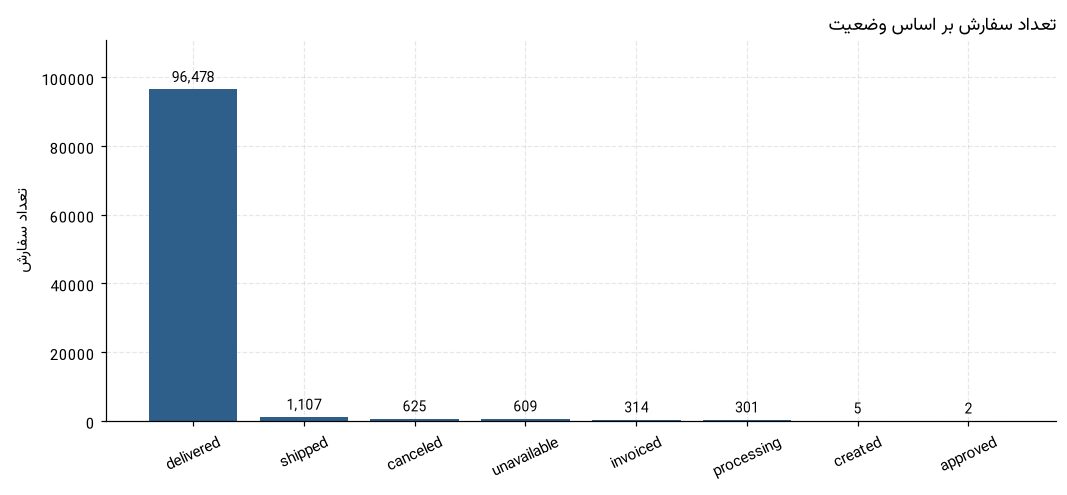

In [9]:
# --- ۵.۱ وضعیت سفارش‌ها ---
status = orders["order_status"].value_counts().rename_axis("وضعیت").to_frame("تعداد")
status["درصد"] = (status["تعداد"] / len(orders) * 100).round(2)
display(status)
bars(status["تعداد"], "تعداد سفارش بر اساس وضعیت", "تعداد سفارش", rotate=25)

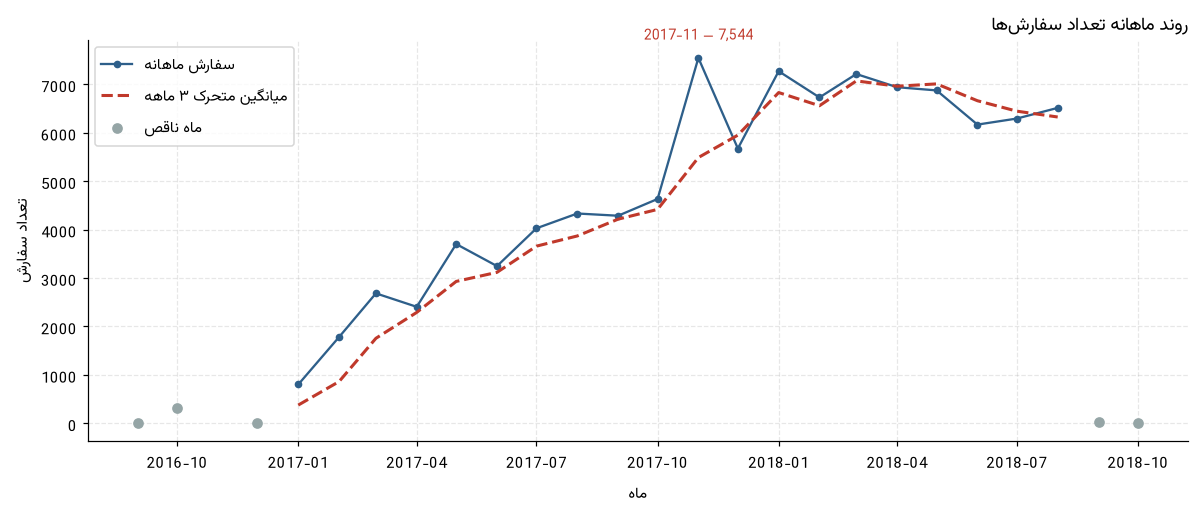

بیشترین ماه: 2017-11 (7,544 سفارش)
کمترین ماه در پنجره: 2017-01 (800 سفارش)


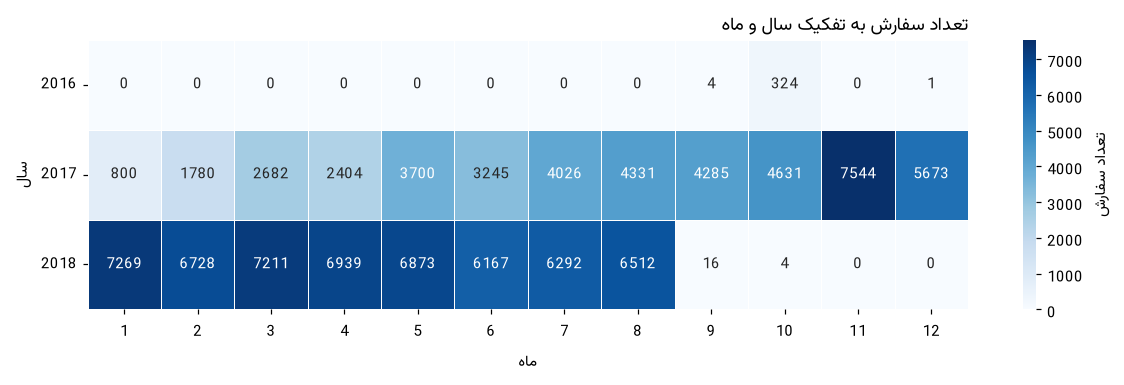

In [10]:
# --- ۵.۲ روند ماهانه و ماتریس سال-ماه ---
monthly = orders.groupby("purchase_ym").size().rename("سفارش").reset_index()
monthly["ماه"] = pd.to_datetime(monthly["purchase_ym"] + "-01")
monthly = monthly.sort_values("ماه")
monthly["میانگین ۳ ماهه"] = monthly["سفارش"].rolling(3).mean()
core = monthly[(monthly["purchase_ym"] >= CORE_START) & (monthly["purchase_ym"] <= CORE_END)]
edge = monthly.drop(core.index)

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(core["ماه"], core["سفارش"], marker="o", markersize=4, color=COLOR_MAIN, label="سفارش ماهانه")
ax.plot(core["ماه"], core["میانگین ۳ ماهه"], "--", linewidth=2, color=COLOR_ACCENT, label="میانگین متحرک ۳ ماهه")
ax.scatter(edge["ماه"], edge["سفارش"], color=COLOR_MUTED, zorder=3, label="ماه ناقص")
peak = core.loc[core["سفارش"].idxmax()]
ax.annotate(f"{peak['purchase_ym']} — {int(peak['سفارش']):,}",
            (peak["ماه"], peak["سفارش"]), textcoords="offset points", xytext=(0, 12),
            ha="center", fontsize=9, color=COLOR_ACCENT)
ax.legend(loc="upper left")
ax.set_title("روند ماهانه تعداد سفارش‌ها", loc="right", fontsize=12)
ax.set_xlabel("ماه")
ax.set_ylabel("تعداد سفارش")
fig.tight_layout()
plt.show()

lowest = core.loc[core["سفارش"].idxmin()]
print("بیشترین ماه:", peak["purchase_ym"], f"({int(peak['سفارش']):,} سفارش)")
print("کمترین ماه در پنجره:", lowest["purchase_ym"], f"({int(lowest['سفارش']):,} سفارش)")

matrix = pd.crosstab(orders["purchase_year"], orders["purchase_month"]).reindex(columns=range(1, 13), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", linewidths=.6, linecolor="white",
            cbar_kws={"label": "تعداد سفارش"}, ax=ax)
ax.set_title("تعداد سفارش به تفکیک سال و ماه", loc="right", fontsize=12)
ax.set_xlabel("ماه")
ax.set_ylabel("سال")
ax.set_yticklabels(matrix.index, rotation=0)
fig.tight_layout()
plt.show()

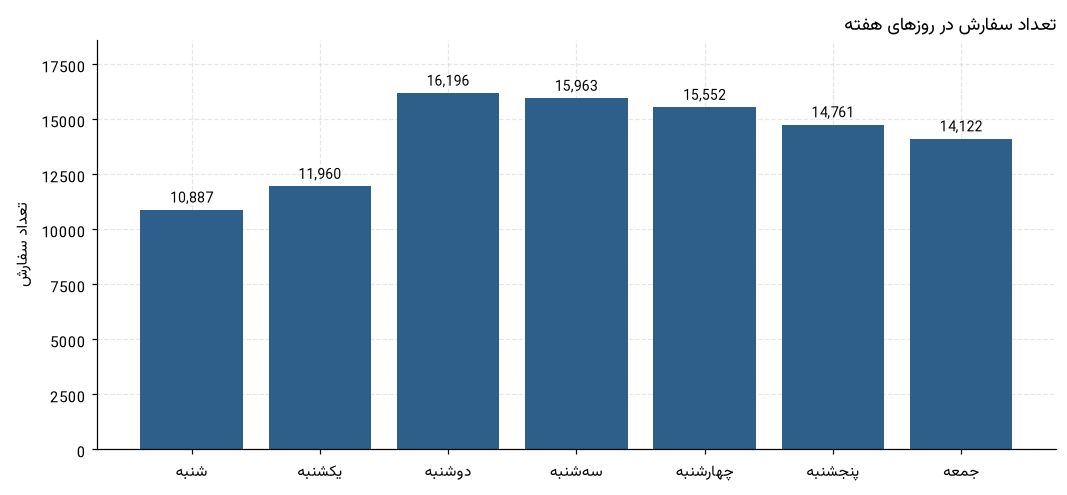

بیشترین روز هفته: دوشنبه (16,196 سفارش)
کمترین روز هفته: شنبه (10,887 سفارش)
نسبت بیشترین به کمترین روز: 1.49


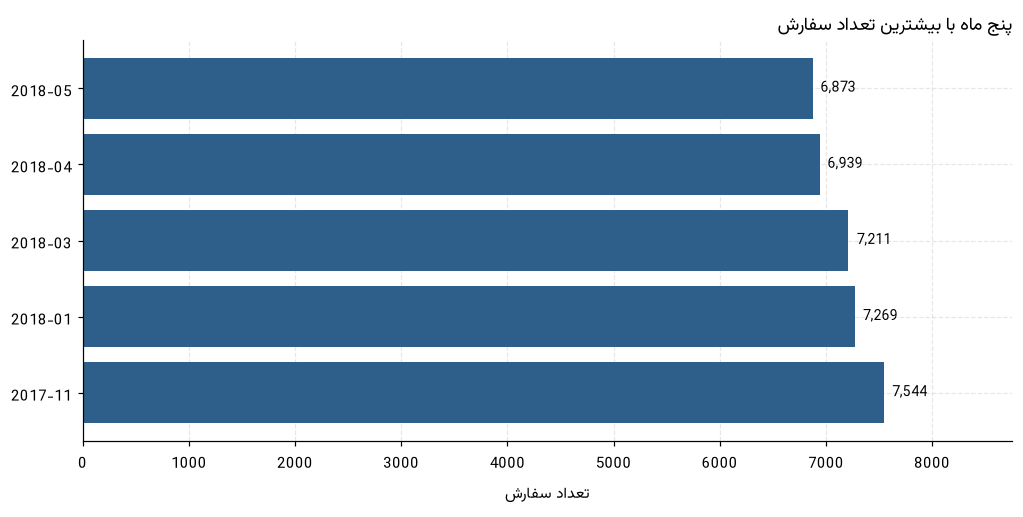

سال این پنج ماه: ['2017', '2018']
ژانویه تا اوت ۲۰۱۷: 22,968 سفارش
ژانویه تا اوت ۲۰۱۸: 53,991 سفارش
رشد هم‌دوره: 135.07%
میانگین شش ماه اول پنجره: 2,435 | شش ماه آخر: 6,666 | تغییر 173.73%


In [11]:
# --- ۵.۳ الگوی هفتگی، ماه‌های پرترافیک و رشد هم‌دوره ---
WEEKDAY_FA = {"Saturday": "شنبه", "Sunday": "یکشنبه", "Monday": "دوشنبه", "Tuesday": "سه‌شنبه",
              "Wednesday": "چهارشنبه", "Thursday": "پنجشنبه", "Friday": "جمعه"}
weekday = orders["purchase_weekday"].value_counts().reindex(list(WEEKDAY_FA)).fillna(0).astype(int)
weekday.index = [WEEKDAY_FA[day] for day in weekday.index]
bars(weekday, "تعداد سفارش در روزهای هفته", "تعداد سفارش")
print("بیشترین روز هفته:", weekday.idxmax(), f"({weekday.max():,} سفارش)")
print("کمترین روز هفته:", weekday.idxmin(), f"({weekday.min():,} سفارش)")
print(f"نسبت بیشترین به کمترین روز: {weekday.max() / weekday.min():.2f}")

top_months = core.nlargest(5, "سفارش").set_index("purchase_ym")["سفارش"].sort_values()
barh(top_months, "پنج ماه با بیشترین تعداد سفارش", "تعداد سفارش")
print("سال این پنج ماه:", sorted({month[:4] for month in top_months.index}))

jan_aug_2017 = int(orders[(orders["purchase_year"] == 2017) & (orders["purchase_month"] <= 8)].shape[0])
jan_aug_2018 = int(orders[(orders["purchase_year"] == 2018) & (orders["purchase_month"] <= 8)].shape[0])
yoy = (jan_aug_2018 / jan_aug_2017 - 1) * 100
first6 = core.head(6)["سفارش"].mean()
last6 = core.tail(6)["سفارش"].mean()
print(f"ژانویه تا اوت ۲۰۱۷: {jan_aug_2017:,} سفارش")
print(f"ژانویه تا اوت ۲۰۱۸: {jan_aug_2018:,} سفارش")
print(f"رشد هم‌دوره: {yoy:.2f}%")
print(f"میانگین شش ماه اول پنجره: {first6:,.0f} | شش ماه آخر: {last6:,.0f} | تغییر {(last6 / first6 - 1) * 100:.2f}%")

<div dir="rtl" align="right">

**تفسیر**

- بیش از ۹۷ درصد سفارش‌ها تحویل شده‌اند و سهم سفارش‌های لغوشده کوچک است؛ بنابراین داده
  برای تحلیل عملکرد عملیات قابل اعتماد است.
- روند ماهانه از ابتدای ۲۰۱۷ صعودی است و در نوامبر ۲۰۱۷ (دوران اوج خرید) به سقف
  می‌رسد. بعد از آن حجم در سطح بالاتری نسبت به سال قبل تثبیت می‌شود؛ رشد هم‌دوره
  ۲۰۱۸ نسبت به ۲۰۱۷ حدود ۱۳۵ درصد است، یعنی تقریباً دو برابر و نیم.
- دو ماه ابتدایی و انتهایی داده کامل نیستند (سپتامبر ۲۰۱۶ و سپتامبر ۲۰۱۸) و در نمودار
  با رنگ روشن جدا شده‌اند؛ برای محاسبه روند از پنجره پیوسته ژانویه ۲۰۱۷ تا اوت ۲۰۱۸
  استفاده می‌کنیم.
- اختلاف روزهای هفته زیاد نیست؛ بیشترین و کمترین روز حدود ۴۰ درصد با هم فاصله دارند و
  الگوی مشخصی از تعطیلی فروش دیده نمی‌شود. پس ظرفیت عملیات در همه روزها تقریباً یکسان
  درگیر است.
- پنج ماه پرترافیک همه در ۲۰۱۷ و ۲۰۱۸ پراکنده‌اند و شامل نوامبر (جمعه سیاه) هستند؛ این
  نشانه وجود فصلی‌بودن در تقاضاست، نه یک جهش تک‌ماهه.

</div>

<div dir="rtl" align="right">

## بخش ۶ — تحلیل مشتریان و بازار جغرافیایی

پرسش تیم بازاریابی این است که مشتریان کجا هستند و بازار تا چه اندازه به چند منطقه
وابسته است. دام مهم این بخش، اشتباه گرفتن ردیف جدول مشتریان با شخص واقعی است.

</div>

In [12]:
# --- ۶.۱ تعداد مشتریان ---
customer_facts = pd.Series({
    "ردیف جدول مشتریان": len(raw["customers"]),
    "شناسه سفارش یکتا": orders["order_id"].nunique(),
    "شخص یکتا (customer_unique_id)": orders["customer_unique_id"].nunique(),
    "سفارش به ازای هر خریدار": round(len(orders) / orders["customer_unique_id"].nunique(), 4),
    "خریدار با بیش از یک سفارش": int((orders.groupby("customer_unique_id").size() > 1).sum()),
    "بیشترین سفارش یک شخص": int(orders.groupby("customer_unique_id").size().max()),
}, name="مقدار")
display(customer_facts.to_frame())
print(f"سهم خریداران تکراری: {(orders.groupby('customer_unique_id').size() > 1).mean() * 100:.2f}%")

,مقدار
ردیف جدول مشتریان,"99,441.00"
شناسه سفارش یکتا,"99,441.00"
شخص یکتا (customer_unique_id),"96,096.00"
سفارش به ازای هر خریدار,1.03
خریدار با بیش از یک سفارش,"2,997.00"
بیشترین سفارش یک شخص,17.00


سهم خریداران تکراری: 3.12%


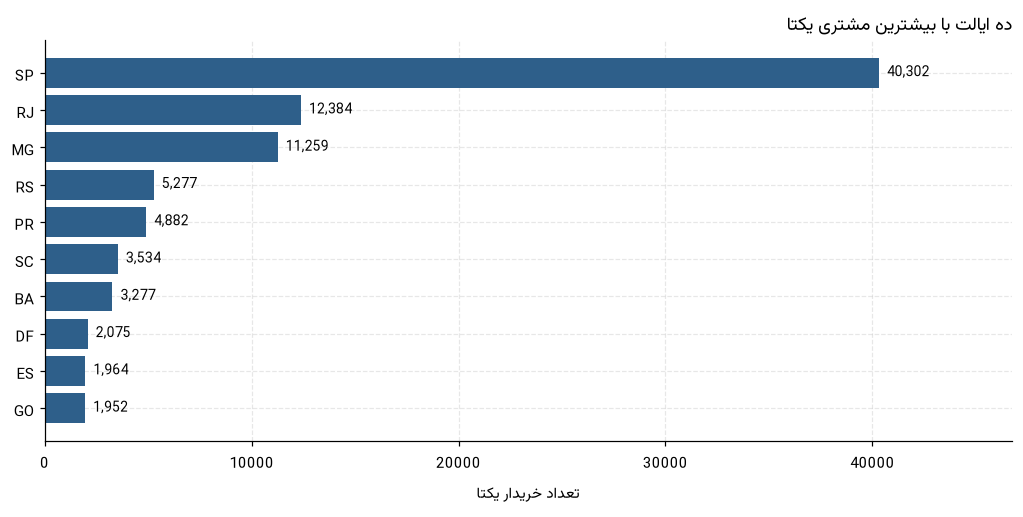

,خریدار یکتا,سهم از کل (درصد)
customer_state,,
SP,40302,41.92
RJ,12384,12.88
MG,11259,11.71
RS,5277,5.49
PR,4882,5.08


سهم پنج ایالت اول از خریداران: 77.08%  |  تعداد ایالت‌ها: 27
بیشترین ایالت: SP (40,302 خریدار)


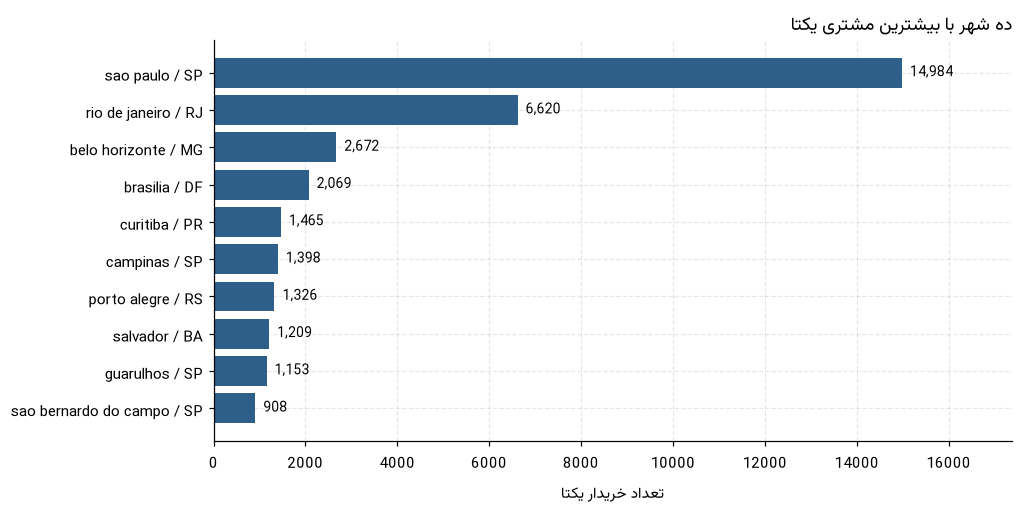

In [13]:
# --- ۶.۲ مشتریان به تفکیک ایالت و شهر ---
state_buyers = orders.groupby("customer_state")["customer_unique_id"].nunique().sort_values(ascending=False)
barh(state_buyers.head(10), "ده ایالت با بیشترین مشتری یکتا", "تعداد خریدار یکتا")

top5 = state_buyers.head(5)
top5_share = top5.sum() / state_buyers.sum() * 100
share_table = pd.DataFrame({
    "خریدار یکتا": top5,
    "سهم از کل (درصد)": (top5 / state_buyers.sum() * 100).round(2),
})
display(share_table)
print(f"سهم پنج ایالت اول از خریداران: {top5_share:.2f}%  |  تعداد ایالت‌ها: {state_buyers.size}")
print("بیشترین ایالت:", state_buyers.index[0], f"({state_buyers.iloc[0]:,} خریدار)")

cities = orders.groupby("city_state")["customer_unique_id"].nunique().sort_values(ascending=False)
barh(cities.head(10), "ده شهر با بیشترین مشتری یکتا", "تعداد خریدار یکتا")

ایالت‌هایی با بیشترین سفارش به ازای هر خریدار:


,خریدار,سفارش,سفارش به خریدار
customer_state,,,
RO,240,253,1.05
AC,77,81,1.05
RJ,12384,12852,1.04


ایالت‌هایی با کمترین سفارش به ازای هر خریدار:


,خریدار,سفارش,سفارش به خریدار
customer_state,,,
AP,67,68,1.01
CE,1313,1336,1.02
RR,45,46,1.02


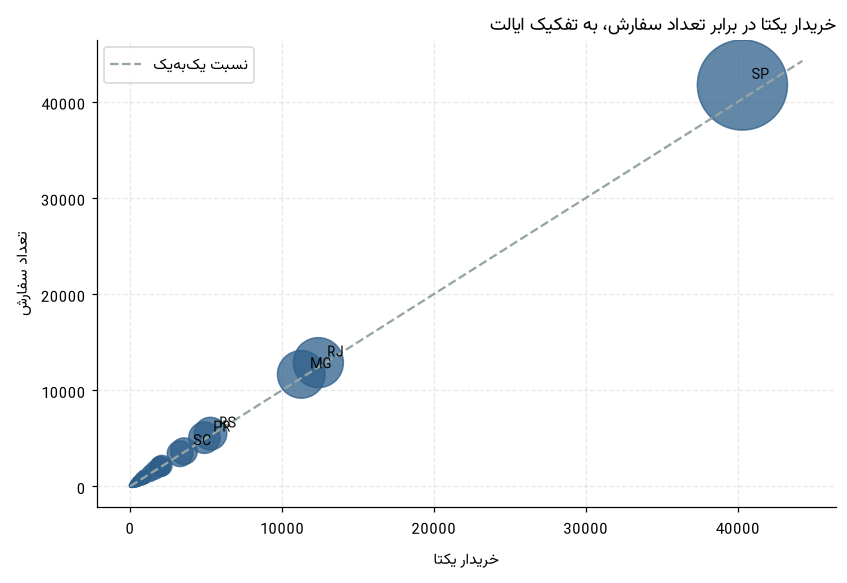

In [14]:
# --- ۶.۳ مقایسه تعداد مشتری و تعداد سفارش در ایالت‌ها ---
state_orders = orders.groupby("customer_state").size()
compare = pd.DataFrame({"خریدار": state_buyers, "سفارش": state_orders}).dropna()
compare["سفارش به خریدار"] = (compare["سفارش"] / compare["خریدار"]).round(3)
print("ایالت‌هایی با بیشترین سفارش به ازای هر خریدار:")
display(compare.sort_values("سفارش به خریدار", ascending=False).head(3))
print("ایالت‌هایی با کمترین سفارش به ازای هر خریدار:")
display(compare.sort_values("سفارش به خریدار").head(3))

fig, ax = plt.subplots(figsize=(7.8, 5.4))
ax.scatter(compare["خریدار"], compare["سفارش"], s=compare["سفارش"] / 12,
           color=COLOR_MAIN, alpha=.75)
limit = compare[["خریدار", "سفارش"]].to_numpy().max() * 1.06
ax.plot([0, limit], [0, limit], "--", color=COLOR_MUTED, label="نسبت یک‌به‌یک")
for state in compare.nlargest(6, "خریدار").index:
    ax.annotate(state, (compare.loc[state, "خریدار"], compare.loc[state, "سفارش"]),
                textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.legend(loc="upper left")
ax.set_title("خریدار یکتا در برابر تعداد سفارش، به تفکیک ایالت", loc="right", fontsize=12)
ax.set_xlabel("خریدار یکتا")
ax.set_ylabel("تعداد سفارش")
fig.tight_layout()
plt.show()

<div dir="rtl" align="right">

**تفسیر**

- ۹۹٬۴۴۱ سفارش به ۹۶٬۰۹۶ شخص می‌رسد؛ یعنی تقریباً هر خریدار فقط یک بار خرید کرده و
  سهم خریداران تکراری حدود ۳ درصد است. این یعنی رشد فروش تا امروز بیشتر از جذب مشتری
  جدید آمده، نه از بازخرید.
- بازار به‌شدت متمرکز است: پنج ایالت اول بیش از سه‌چهارم خریداران را دارند و سائوپائولو
  به‌تنهایی حدود ۴۲ درصد بازار است. همین تمرکز در سطح شهر هم دیده می‌شود و چند شهر
  بزرگ، بیشتر مشتریان را در خود دارند.
- در نمودار مقایسه‌ای، بیشتر ایالت‌ها نزدیک خط یک‌به‌یک هستند؛ یعنی تعداد سفارش با
  تعداد مشتری متناسب است. ایالت‌هایی که بالای خط قرار می‌گیرند خریدار کمتری دارند اما
  همان خریدار چند سفارش ثبت کرده است.
- هر ایالت دور از خط یک‌به‌یک و با تعداد مشتری کم، نامزد بررسی بازار است؛ اما تعداد کم
  مشتری به‌تنهایی دلیل وجود فرصت رشد نیست و باید هزینه ارسال و رقابت هم سنجیده شود.

</div>

In [15]:
# --- ۶.۴ نرخ بازگشت خریدار در بازه ۹۰ روزه (کوهورت) ---
first_purchase = orders.groupby("customer_unique_id")["order_purchase_timestamp"].min().rename("first_ts")
sequence = orders[["customer_unique_id", "order_purchase_timestamp"]].copy()
sequence["step"] = sequence.groupby("customer_unique_id")["order_purchase_timestamp"].rank(method="first")
second_purchase = sequence[sequence["step"] == 2].merge(first_purchase, on="customer_unique_id")
second_purchase["gap_days"] = (
    second_purchase["order_purchase_timestamp"] - second_purchase["first_ts"]
).dt.days

cohort = first_purchase[(first_purchase >= "2017-01-01") & (first_purchase <= "2018-05-31")]
repeat_90 = second_purchase.loc[second_purchase["gap_days"] <= 90, "customer_unique_id"].nunique()
cohort_facts = pd.Series({
    "خریداران کوهورت (اولین خرید ۲۰۱۷-۰۱ تا ۲۰۱۸-۰۵)": len(cohort),
    "خریدارانی که تا ۹۰ روز سفارش دوم دادند": int(repeat_90),
    "نرخ بازگشت ۹۰ روزه (درصد)": round(repeat_90 / len(cohort) * 100, 2),
    "سهم کل خریداران با بیش از یک سفارش (درصد)": round(
        (orders.groupby("customer_unique_id").size() > 1).mean() * 100, 2
    ),
    "میانه فاصله سفارش اول تا دوم (روز)": round(float(second_purchase["gap_days"].median()), 1),
}, name="مقدار")
display(cohort_facts.to_frame())

,مقدار
خریداران کوهورت (اولین خرید ۲۰۱۷-۰۱ تا ۲۰۱۸-۰۵),"77,354.00"
خریدارانی که تا ۹۰ روز سفارش دوم دادند,"2,063.00"
نرخ بازگشت ۹۰ روزه (درصد),2.67
سهم کل خریداران با بیش از یک سفارش (درصد),3.12
میانه فاصله سفارش اول تا دوم (روز),27.00


<div dir="rtl" align="right">

**چرا نرخ بازگشت ۹۰ روزه؟**

سهم «خریدار تکراری» در کل داده (بخش ۶.۱) به طول کل دوره نگاه می‌کند و با یک بازه دو
ساله طبیعتاً کوچک می‌شود. معیار دقیق‌تر، کوهورت است: خریدارانی که اولین خریدشان در
بازه‌ای مشخص ثبت شده و فرصت کافی برای خرید دوم داشته‌اند. نرخ بازگشت ۹۰ روزه در همین
جدول محاسبه شده و کمتر از ۳ درصد است؛ یعنی مسئله «بازخرید» ساختاری است و به یک
دسته‌بندی یا یک ماه خاص مربوط نیست. همین عدد مبنای پیشنهاد ۳ در بخش ۱۴.۵ است.

</div>

<div dir="rtl" align="right">

## بخش ۷ — تحلیل محصولات و عملکرد فروش

تیم فروش می‌خواهد بداند تقاضا روی کدام دسته‌بندی‌ها متمرکز است و مبلغ فروش در کدام
دسته‌بندی‌ها بیشتر است. تفاوت این دو فهرست، همان جایی است که تصمیم‌گیری فقط بر پایه
تعداد فروش گمراه‌کننده می‌شود.

</div>

تعداد دسته‌بندی دارای فروش: 73
مجموع اقلام فروخته‌شده: 111,047


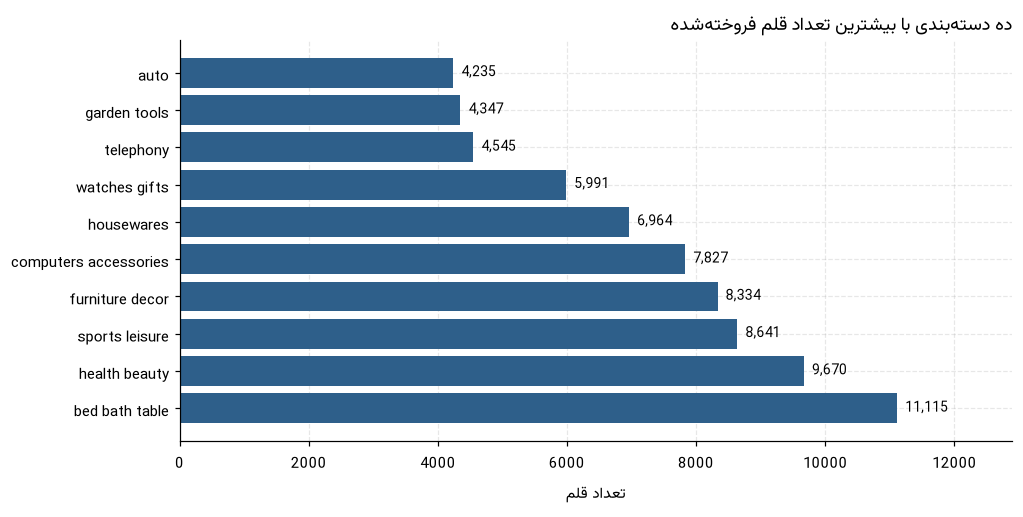

,n_items,revenue
category_label,,
bed_bath_table,11115,"1,036,988.68"
health_beauty,9670,"1,258,681.34"
sports_leisure,8641,"988,048.97"
furniture_decor,8334,"729,762.49"
computers_accessories,7827,"911,954.32"


In [16]:
# --- ۷.۱ تعداد اقلام فروخته‌شده در هر دسته‌بندی ---
category = (items.groupby("category_label")
            .agg(n_items=("order_item_id", "count"),
                 revenue=("price", "sum"),
                 mean_price=("price", "mean"),
                 mean_freight=("freight_value", "mean"))
            .reset_index())
category = category[category["category_label"] != "unknown"]
print("تعداد دسته‌بندی دارای فروش:", len(category))
print("مجموع اقلام فروخته‌شده:", f"{category['n_items'].sum():,}")

by_items = category.nlargest(10, "n_items").set_index("category_label")["n_items"].sort_values()
barh(by_items, "ده دسته‌بندی با بیشترین تعداد قلم فروخته‌شده", "تعداد قلم")
display(category.nlargest(5, "n_items").set_index("category_label")[["n_items", "revenue"]].round(2))

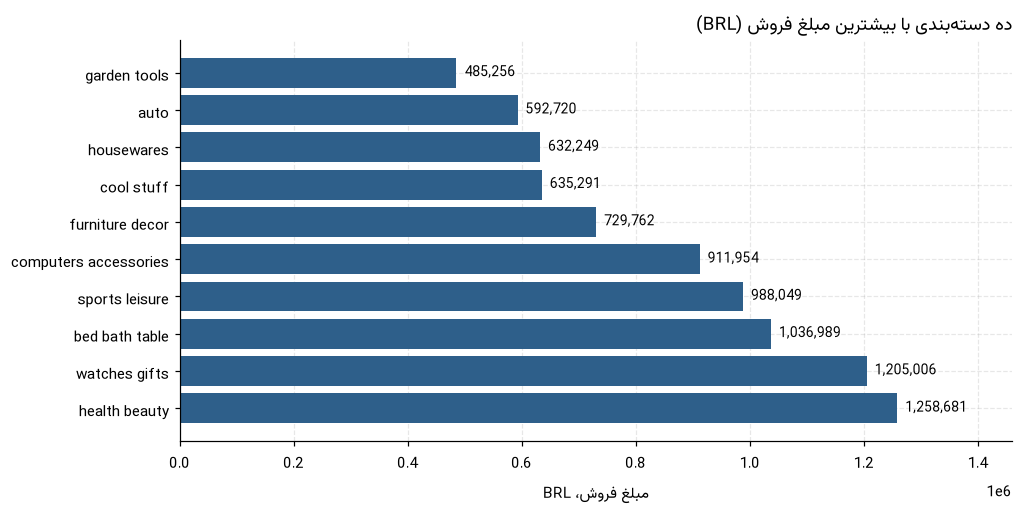

دسته‌بندی‌هایی که رتبه تعداد با رتبه مبلغ فاصله زیادی دارند:


,n_items,revenue,rank_items,rank_revenue,rank_gap
category_label,,,,,
drinks,379,"22,428.70",31,46,-15
food_drink,278,"15,179.48",37,51,-14
food,510,"29,393.41",28,41,-13
books_technical,267,"19,096.06",39,49,-10
agro_industry_and_commerce,212,"72,530.47",44,29,15
home_appliances_2,238,"113,317.74",42,26,16
small_appliances_home_oven_and_coffee,76,"47,445.71",55,35,20
computers,203,"222,963.13",46,17,29


In [17]:
# --- ۷.۲ مبلغ فروش و مقایسه رتبه‌ها ---
by_revenue = category.nlargest(10, "revenue").set_index("category_label")["revenue"].sort_values()
barh(by_revenue, "ده دسته‌بندی با بیشترین مبلغ فروش (BRL)", "مبلغ فروش، BRL")

category["rank_items"] = category["n_items"].rank(ascending=False, method="min").astype(int)
category["rank_revenue"] = category["revenue"].rank(ascending=False, method="min").astype(int)
category["rank_gap"] = category["rank_items"] - category["rank_revenue"]
gap = category.reindex(category["rank_gap"].abs().nlargest(8).index)
print("دسته‌بندی‌هایی که رتبه تعداد با رتبه مبلغ فاصله زیادی دارند:")
display(gap[["category_label", "n_items", "revenue", "rank_items", "rank_revenue", "rank_gap"]]
        .sort_values("rank_gap").set_index("category_label").round(2))

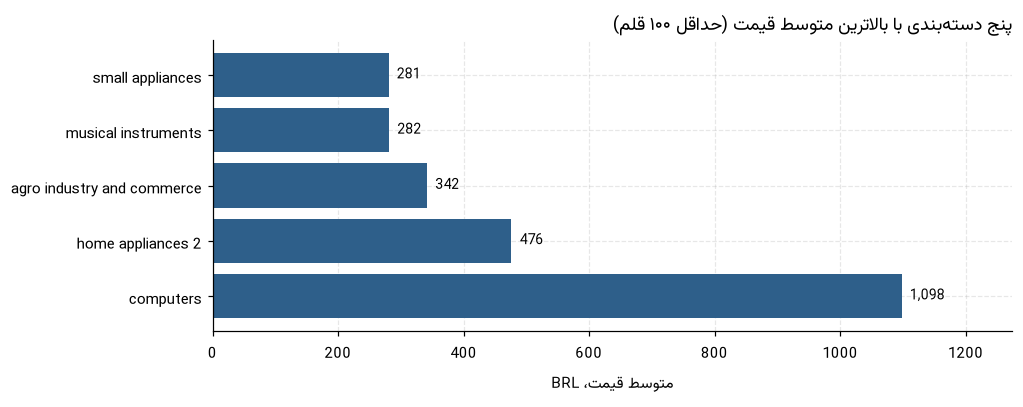

آیا این دسته‌بندی‌ها در فهرست پرفروش‌ترین‌ها هم هستند؟


,mean_price,n_items,rank_items
category_label,,,
computers,"1,098.34",203,46
home_appliances_2,476.12,238,42
agro_industry_and_commerce,342.12,212,44
musical_instruments,281.62,680,24
small_appliances,280.78,679,25


,revenue,سهم_درصد
category_label,,
health_beauty,"1,258,681.34",9.38
watches_gifts,"1,205,005.68",8.98
bed_bath_table,"1,036,988.68",7.73
sports_leisure,"988,048.97",7.37
computers_accessories,"911,954.32",6.80


سهم پنج دسته‌بندی اول از مبلغ فروش: 40.27%  |  مبلغ کل: 13,412,108.42 BRL


In [18]:
# --- ۷.۳ متوسط قیمت و سهم از فروش ---
pricey = category[category["n_items"] >= 100].nlargest(5, "mean_price")
barh(pricey.set_index("category_label")["mean_price"].sort_values(),
     "پنج دسته‌بندی با بالاترین متوسط قیمت (حداقل ۱۰۰ قلم)", "متوسط قیمت، BRL",
     figsize=(9.4, 3.8))
print("آیا این دسته‌بندی‌ها در فهرست پرفروش‌ترین‌ها هم هستند؟")
display(pricey[["category_label", "mean_price", "n_items", "rank_items"]].set_index("category_label").round(2))

top5_revenue = category.nlargest(5, "revenue")
share = top5_revenue["revenue"].sum() / category["revenue"].sum() * 100
top5_table = top5_revenue.assign(سهم_درصد=(top5_revenue["revenue"] / category["revenue"].sum() * 100).round(2))
display(top5_table[["category_label", "revenue", "سهم_درصد"]].set_index("category_label"))
print(f"سهم پنج دسته‌بندی اول از مبلغ فروش: {share:.2f}%  |  مبلغ کل: {category['revenue'].sum():,.2f} BRL")

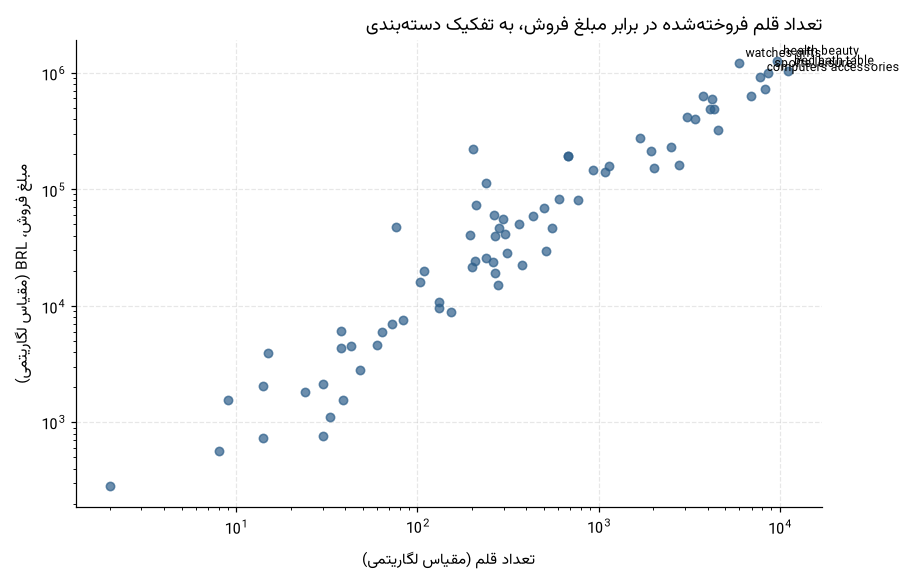

دسته‌بندی‌های پرتعداد با مبلغ فروش پایین‌تر:


,n_items,revenue,rank_revenue
category_label,,,


In [19]:
# --- ۷.۴ تعداد قلم در برابر مبلغ فروش ---
fig, ax = plt.subplots(figsize=(8.4, 5.4))
ax.scatter(category["n_items"], category["revenue"], s=30, alpha=.7, color=COLOR_MAIN)
ax.set_xscale("log")
ax.set_yscale("log")
for name in category.nlargest(5, "revenue")["category_label"]:
    row = category[category["category_label"] == name].iloc[0]
    ax.annotate(name.replace("_", " "), (row["n_items"], row["revenue"]), fontsize=8,
                textcoords="offset points", xytext=(4, 4))
ax.set_title("تعداد قلم فروخته‌شده در برابر مبلغ فروش، به تفکیک دسته‌بندی", loc="right", fontsize=12)
ax.set_xlabel("تعداد قلم (مقیاس لگاریتمی)")
ax.set_ylabel("مبلغ فروش، BRL (مقیاس لگاریتمی)")
fig.tight_layout()
plt.show()

above = category[(category["rank_items"] <= 10) & (category["rank_revenue"] > 15)]
print("دسته‌بندی‌های پرتعداد با مبلغ فروش پایین‌تر:")
display(above[["category_label", "n_items", "revenue", "rank_revenue"]].set_index("category_label"))

<div dir="rtl" align="right">

**تفسیر**

- ۷۳ دسته‌بندی دارای فروش داریم. پرتعدادترین دسته‌بندی `bed_bath_table` است، اما در
  مبلغ فروش جایگاه اول را ندارد؛ دسته‌بندی‌هایی مثل `health_beauty` و `watches_gifts`
  با تعداد کمتر، مبلغ بیشتری تولید می‌کنند.
- مقایسه رتبه‌ها نشان می‌دهد چند دسته‌بندی با حجم بالا در مبلغ فروش جایگاه پایین‌تری
  دارند؛ یعنی قیمت واحد پایین‌تری دارند و حاشیه کمتری روی هر قلم می‌سازند. تصمیم
  بازاریابی برای این گروه باید بر «افزایش سبد خرید» متمرکز باشد، نه تخفیف حجمی.
- دسته‌بندی‌های گران‌قیمت لزوماً پرفروش نیستند و برخی حتی در ۱۰ دسته‌بندی اول حجم هم
  قرار نمی‌گیرند؛ این گروه برای فروش مکمل و لوازم جانبی مناسب‌ترند.
- پنج دسته‌بندی اول حدود ۴۰ درصد مبلغ فروش را می‌سازند. این تمرکز یعنی هر اختلال در
  تأمین یا قیمت همین چند دسته‌بندی، مستقیماً روی درآمد اثر می‌گذارد.

**نکته روش‌شناسی:** مبلغ فروش از ستون `price` جدول اقلام محاسبه شده و هزینه ارسال
(`freight_value`) را شامل نمی‌شود؛ پس با درآمد خالص شرکت یکی نیست.

</div>

<div dir="rtl" align="right">

## بخش ۸ — تحلیل رفتار پرداخت مشتریان

در این بخش دو نکته روش‌شناختی مهم است: هر ردیف جدول پرداخت یک تراکنش است، نه یک سفارش؛
و مبلغ پرداخت‌شده با مبلغ اقلام یکی نیست، چون هزینه ارسال هم پرداخت می‌شود.

</div>

,مقدار
ردیف پرداخت (تراکنش),103886
سفارش یکتا با پرداخت,99440
سفارش در جدول سفارش,99441
مجموع مبلغ پرداخت‌شده (BRL),"16,008,872.12"
مجموع مبلغ اقلام (BRL),"13,591,643.70"
مجموع هزینه ارسال (BRL),"2,251,909.54"


,تراکنش,مبلغ_کل,میانگین,سهم_تراکنش_درصد,سهم_مبلغ_درصد
payment_type,,,,,
credit_card,76795,"12,542,084.19",163.32,73.92,78.34
boleto,19784,"2,869,361.27",145.03,19.04,17.92
voucher,5775,"379,436.87",65.70,5.56,2.37
debit_card,1529,"217,989.79",142.57,1.47,1.36
not_defined,3,0.00,0.00,0.00,0.00


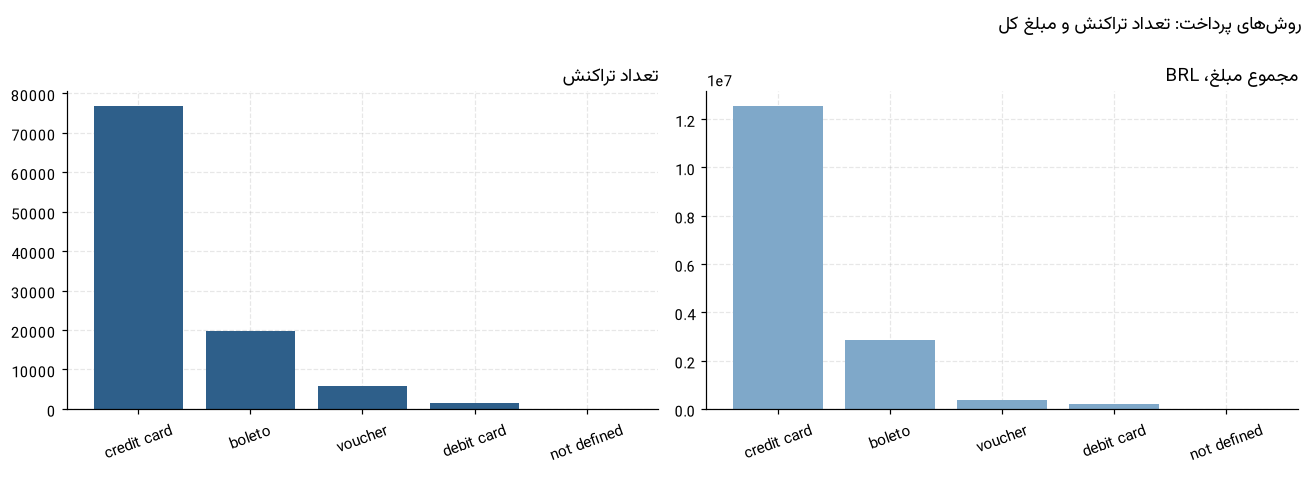

In [20]:
# --- ۸.۱ روش‌های پرداخت ---
payments = raw["payments"].copy()
payment_facts = pd.Series({
    "ردیف پرداخت (تراکنش)": len(payments),
    "سفارش یکتا با پرداخت": payments["order_id"].nunique(),
    "سفارش در جدول سفارش": len(orders),
    "مجموع مبلغ پرداخت‌شده (BRL)": f"{payments['payment_value'].sum():,.2f}",
    "مجموع مبلغ اقلام (BRL)": f"{items['price'].sum():,.2f}",
    "مجموع هزینه ارسال (BRL)": f"{items['freight_value'].sum():,.2f}",
}, name="مقدار")
display(payment_facts.to_frame())

by_type = (payments.groupby("payment_type")
           .agg(تراکنش=("payment_value", "size"),
                مبلغ_کل=("payment_value", "sum"),
                میانگین=("payment_value", "mean")))
by_type["سهم_تراکنش_درصد"] = (by_type["تراکنش"] / len(payments) * 100).round(2)
by_type["سهم_مبلغ_درصد"] = (by_type["مبلغ_کل"] / payments["payment_value"].sum() * 100).round(2)
display(by_type.sort_values("تراکنش", ascending=False).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ordered = by_type.sort_values("تراکنش", ascending=False)
labels = [name.replace("_", " ") for name in ordered.index]
axes[0].bar(labels, ordered["تراکنش"], color=COLOR_MAIN)
axes[0].set_title("تعداد تراکنش", loc="right")
axes[1].bar(labels, ordered["مبلغ_کل"], color="#7FA8C9")
axes[1].set_title("مجموع مبلغ، BRL", loc="right")
for axis in axes:
    axis.tick_params(axis="x", rotation=20)
fig.suptitle("روش‌های پرداخت: تعداد تراکنش و مبلغ کل", x=0.99, ha="right", fontsize=12)
fig.tight_layout()
plt.show()

,تراکنش,درصد
اقساط,,
0,2,0.00
1,52546,50.58
2,12413,11.95
3,10461,10.07
4,7098,6.83
5,5239,5.04
6,3920,3.77
7,1626,1.57
8,4268,4.11


پرداخت بدون قسط یا یک‌قسطی: 50.58%
پرداخت با صفر قسط: 2 تراکنش
پرتکرارترین تعداد اقساط: 1 (52,546 تراکنش)
بیشترین تعداد اقساط ثبت‌شده: 24


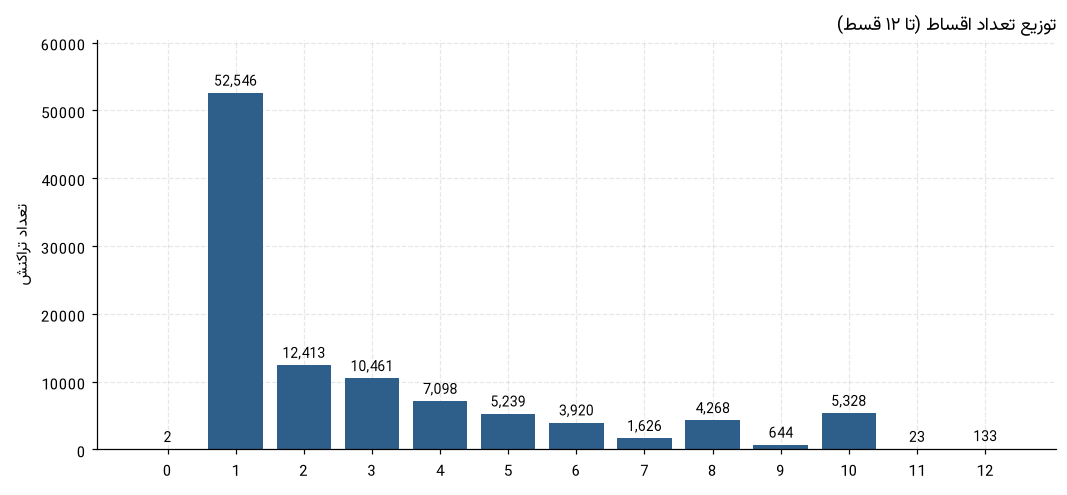

In [21]:
# --- ۸.۲ توزیع تعداد اقساط ---
installments = payments["payment_installments"].value_counts().sort_index()
installments.index = installments.index.astype(int)
install_table = pd.DataFrame({
    "اقساط": installments.index,
    "تراکنش": installments.values,
    "درصد": (installments.values / len(payments) * 100).round(2),
}).set_index("اقساط")
display(install_table)

share_single = (payments["payment_installments"] <= 1).mean() * 100
print(f"پرداخت بدون قسط یا یک‌قسطی: {share_single:.2f}%")
print("پرداخت با صفر قسط:", int((payments["payment_installments"] == 0).sum()), "تراکنش")
print("پرتکرارترین تعداد اقساط:", int(installments.idxmax()), f"({installments.max():,} تراکنش)")
print("بیشترین تعداد اقساط ثبت‌شده:", int(installments.index.max()))

bars(installments[installments.index <= 12].rename("تراکنش"),
     "توزیع تعداد اقساط (تا ۱۲ قسط)", "تعداد تراکنش")

,تراکنش,میانگین_اقساط,چندقسطی_درصد
بازه مبلغ,,,
-0 تا 35,10428,1.21,15.06
35 تا 49,10362,1.65,30.96
49 تا 64,10377,1.95,36.38
64 تا 80,10388,2.25,42.93
80 تا 100,10555,2.55,45.33
100 تا 123,10222,2.97,56.69
123 تا 154,10390,3.08,59.10
154 تا 196,10390,3.50,65.81
196 تا 297,10386,4.05,68.67


همبستگی اسپیرمن مبلغ پرداخت و تعداد اقساط: 0.4111
همین همبستگی فقط در کارت اعتباری: 0.4776


,میانگین_اقساط,چندقسطی_درصد
payment_type,,
credit_card,3.51,66.85
boleto,1.00,0.00
debit_card,1.00,0.00
not_defined,1.00,0.00
voucher,1.00,0.00


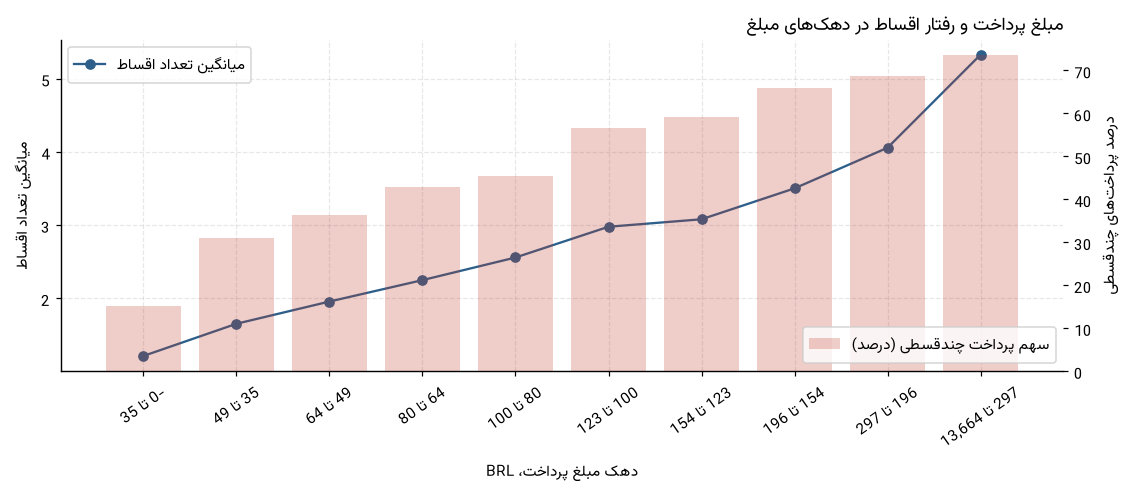

In [22]:
# --- ۸.۳ رابطه مبلغ پرداخت و تعداد اقساط ---
payment_rho = payments[["payment_value", "payment_installments"]].corr(method="spearman").iloc[0, 1]
payments["value_decile"] = pd.qcut(payments["payment_value"], 10, duplicates="drop")
deciles = (payments.groupby("value_decile", observed=True)
           .agg(تراکنش=("payment_value", "size"),
                میانگین_اقساط=("payment_installments", "mean"),
                چندقسطی_درصد=("payment_installments", lambda series: (series > 1).mean() * 100)))
deciles["بازه مبلغ"] = [f"{interval.left:,.0f} تا {interval.right:,.0f}" for interval in deciles.index]
display(deciles.reset_index(drop=True).set_index("بازه مبلغ").round(2))
print(f"همبستگی اسپیرمن مبلغ پرداخت و تعداد اقساط: {payment_rho:.4f}")

card_only = payments[payments["payment_type"] == "credit_card"]
card_rho = card_only[["payment_value", "payment_installments"]].corr(method="spearman").iloc[0, 1]
print(f"همین همبستگی فقط در کارت اعتباری: {card_rho:.4f}")

by_type_installments = (payments.groupby("payment_type")
                        .agg(میانگین_اقساط=("payment_installments", "mean"),
                             چندقسطی_درصد=("payment_installments", lambda series: (series > 1).mean() * 100)))
display(by_type_installments.round(2).sort_values("میانگین_اقساط", ascending=False))

fig, ax = plt.subplots(figsize=(10.4, 4.6))
ax.plot(deciles["بازه مبلغ"], deciles["میانگین_اقساط"], marker="o", color=COLOR_MAIN,
        label="میانگین تعداد اقساط")
ax.set_ylabel("میانگین تعداد اقساط")
ax2 = ax.twinx()
ax2.bar(deciles["بازه مبلغ"], deciles["چندقسطی_درصد"], alpha=.25, color=COLOR_ACCENT,
        label="سهم پرداخت چندقسطی (درصد)")
ax2.set_ylabel("درصد پرداخت‌های چندقسطی")
ax2.grid(False)
ax.set_title("مبلغ پرداخت و رفتار اقساط در دهک‌های مبلغ", loc="right", fontsize=12)
ax.set_xlabel("دهک مبلغ پرداخت، BRL")
ax.tick_params(axis="x", rotation=35)
ax.legend(loc="upper left")
ax2.legend(loc="lower right")
fig.tight_layout()
plt.show()

<div dir="rtl" align="right">

**تفسیر**

- کارت اعتباری با فاصله زیاد پرکاربردترین روش است و پس از آن بولتو (رسید بانکی) قرار
  دارد. کارت اعتباری هم از نظر تعداد و هم از نظر مبلغ، ستون اصلی پرداخت‌هاست؛ بنابراین
  هر اختلال در درگاه کارت، مستقیماً فروش را متوقف می‌کند.
- حدود نیمی از تراکنش‌ها یک‌قسطی یا بدون قسط هستند و پرتکرارترین حالت یک قسط است. پس
  فرهنگ خرید اقساطی وجود دارد، اما اکثریت هنوز یک‌جا پرداخت می‌کنند.
- رابطه مبلغ و تعداد اقساط مثبت و متوسط است (اسپیرمن حدود ۰٫۴۱ در کل تراکنش‌ها و
  بالاتر در کارت اعتباری). از دهک کم‌مبلغ به دهک پرمبلغ، میانگین اقساط و سهم پرداخت
  چندقسطی به‌طور پیوسته بالا می‌رود؛ این رابطه گام‌به‌گام است، نه پرشی.
- جمع مبلغ پرداخت‌ها از جمع مبلغ اقلام بیشتر است و اختلاف تقریباً برابر مجموع هزینه
  ارسال است؛ این تطبیق نشان می‌دهد محاسبه مبلغ در دو جدول سازگار است.

</div>

<div dir="rtl" align="right">

## بخش ۹ — بررسی عملکرد ارسال سفارش‌ها

دو شاخص متفاوت داریم و نباید با هم اشتباه شوند: **مدت تحویل** (فاصله ثبت تا تحویل) و
**تأخیر** (تحویل واقعی نسبت به تاریخ تخمینی). ممکن است سفارشی ۲۰ روز طول بکشد اما
زودتر از موعد برسد.

</div>

,مقدار
تعداد سفارش,"96,470.00"
میانگین (روز),12.56
میانه (روز),10.22
کمینه (روز),0.53
بیشینه (روز),209.63
صدک ۹۰ (روز),23.10
صدک ۹۹ (روز),46.05
چولگی,3.83


اختلاف میانگین و میانه: 2.34 روز


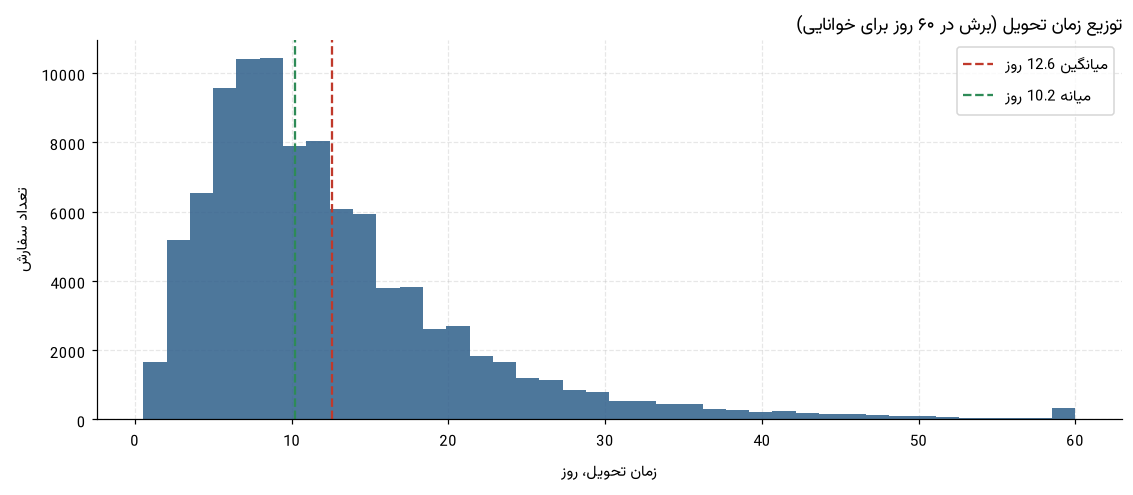

تحویل تا ۷ روز: 27.00%  |  بیش از ۳۰ روز: 4.72%


In [23]:
# --- ۹.۱ مدت زمان تحویل ---
duration = delivered["delivery_days"]
distribution = pd.Series({
    "تعداد سفارش": len(duration),
    "میانگین (روز)": round(duration.mean(), 2),
    "میانه (روز)": round(duration.median(), 2),
    "کمینه (روز)": round(duration.min(), 2),
    "بیشینه (روز)": round(duration.max(), 2),
    "صدک ۹۰ (روز)": round(duration.quantile(.90), 2),
    "صدک ۹۹ (روز)": round(duration.quantile(.99), 2),
    "چولگی": round(duration.skew(), 2),
}, name="مقدار")
display(distribution.to_frame())
print(f"اختلاف میانگین و میانه: {duration.mean() - duration.median():.2f} روز")

fig, ax = plt.subplots(figsize=(10.4, 4.6))
ax.hist(duration.clip(upper=60), bins=40, color=COLOR_MAIN, alpha=.85)
ax.axvline(duration.mean(), color=COLOR_ACCENT, linestyle="--", label=f"میانگین {duration.mean():.1f} روز")
ax.axvline(duration.median(), color="#2E8B57", linestyle="--", label=f"میانه {duration.median():.1f} روز")
ax.legend()
ax.set_title("توزیع زمان تحویل (برش در ۶۰ روز برای خوانایی)", loc="right", fontsize=12)
ax.set_xlabel("زمان تحویل، روز")
ax.set_ylabel("تعداد سفارش")
fig.tight_layout()
plt.show()
print(f"تحویل تا ۷ روز: {(duration <= 7).mean() * 100:.2f}%  |  بیش از ۳۰ روز: {(duration > 30).mean() * 100:.2f}%")

,تعداد,درصد
زودتر از موعد,88644,91.89
دیرکرددار,6534,6.77
به‌موقع,1292,1.34


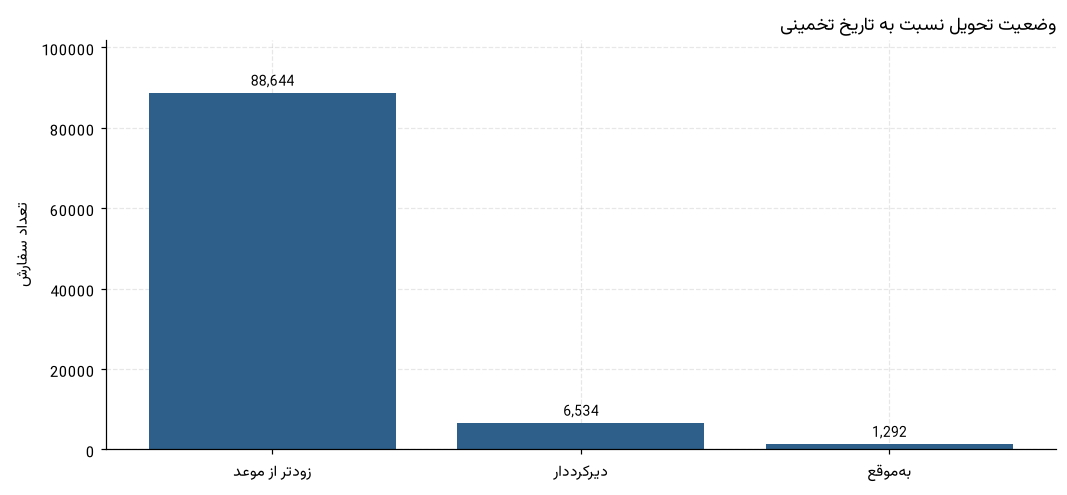

,مقدار
سفارش دیرکرددار,"6,534.00"
سهم از تحویل‌شده (درصد),6.77
میانگین تأخیر (روز),10.62
میانه تأخیر (روز),7.00
تأخیر بیش از ۷ روز,"2,862.00"
تأخیر بیش از ۱۵ روز,"1,225.00"


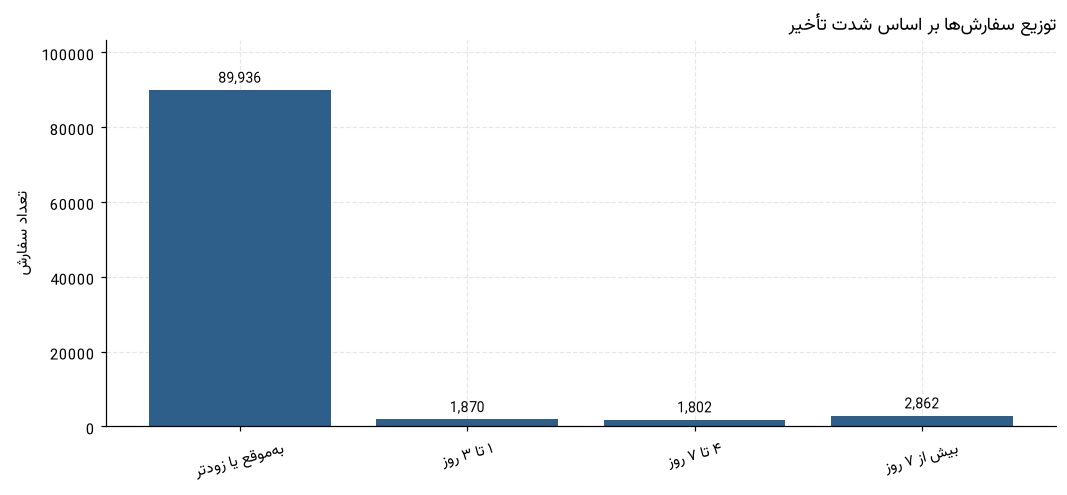

In [24]:
# --- ۹.۲ مقایسه تحویل با تاریخ تخمینی ---
CLASS_FA = {"early": "زودتر از موعد", "on_time": "به‌موقع", "late": "دیرکرددار"}
class_table = delivered["delivery_class"].value_counts().rename_axis("طبقه").to_frame("تعداد")
class_table["درصد"] = (class_table["تعداد"] / len(delivered) * 100).round(2)
class_table.index = [CLASS_FA[key] for key in class_table.index]
display(class_table)
bars(class_table["تعداد"], "وضعیت تحویل نسبت به تاریخ تخمینی", "تعداد سفارش")

late_orders = delivered[delivered["delivery_class"] == "late"]
late_facts = pd.Series({
    "سفارش دیرکرددار": len(late_orders),
    "سهم از تحویل‌شده (درصد)": round(len(late_orders) / len(delivered) * 100, 2),
    "میانگین تأخیر (روز)": round(late_orders["delay_days"].mean(), 2),
    "میانه تأخیر (روز)": float(late_orders["delay_days"].median()),
    "تأخیر بیش از ۷ روز": int((late_orders["delay_days"] > 7).sum()),
    "تأخیر بیش از ۱۵ روز": int((late_orders["delay_days"] > 15).sum()),
}, name="مقدار")
display(late_facts.to_frame())

bucket_counts = delivered["delay_bucket"].value_counts().reindex(BUCKET_ORDER)
bucket_counts.index = [BUCKET_FA[key] for key in bucket_counts.index]
bars(bucket_counts, "توزیع سفارش‌ها بر اساس شدت تأخیر", "تعداد سفارش", rotate=15)

ایالت با حداقل ۱۰۰ سفارش: 24 از 27


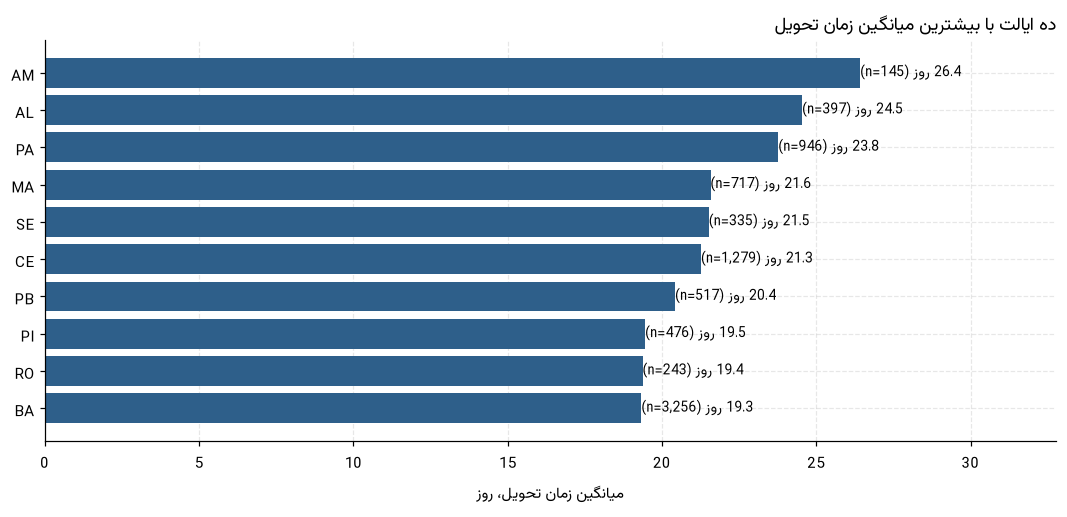

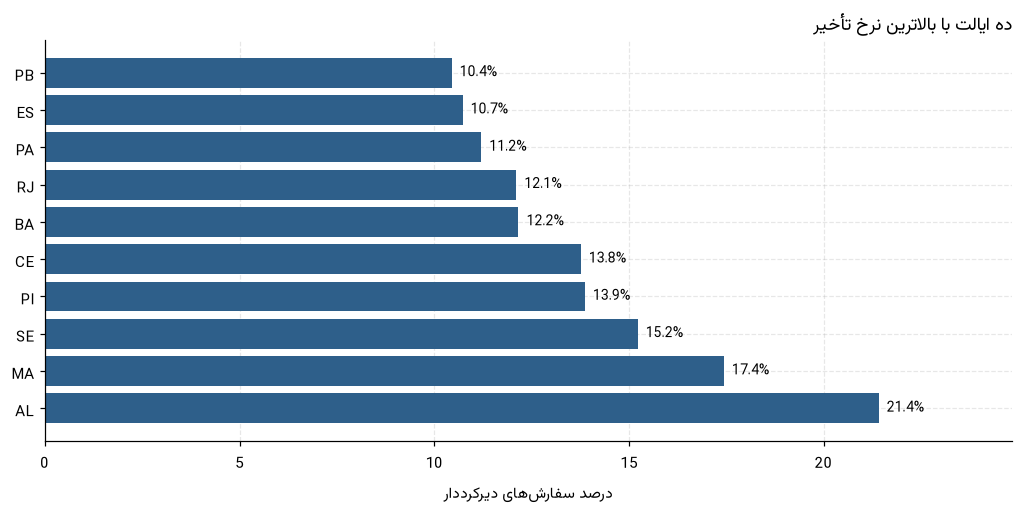

بدترین ایالت از نظر نرخ تأخیر: AL (21.4% از 397 سفارش)


In [25]:
# --- ۹.۳ عملکرد جغرافیایی و روند زمانی ---
state_delivery = (delivered.groupby("customer_state")
                  .agg(سفارش=("order_id", "size"),
                       میانگین_روز=("delivery_days", "mean"),
                       نرخ_تأخیر_درصد=("delivery_class", lambda series: (series == "late").mean() * 100),
                       میانگین_تأخیر=("delay_days", lambda series: series[series > 0].mean())))
eligible_states = state_delivery[state_delivery["سفارش"] >= 100].copy()
print("ایالت با حداقل ۱۰۰ سفارش:", len(eligible_states), "از", len(state_delivery))

slow_states = eligible_states.nlargest(10, "میانگین_روز").sort_values("میانگین_روز")
fig, ax = plt.subplots(figsize=(9.8, 4.8))
ax.barh(slow_states.index, slow_states["میانگین_روز"], color=COLOR_MAIN)
for row, state in enumerate(slow_states.index):
    value = slow_states.loc[state, "میانگین_روز"]
    count = int(slow_states.loc[state, "سفارش"])
    ax.text(value, row, f"  {value:.1f} روز (n={count:,})", va="center", fontsize=9)
ax.set_title("ده ایالت با بیشترین میانگین زمان تحویل", loc="right", fontsize=12)
ax.set_xlabel("میانگین زمان تحویل، روز")
ax.margins(x=0.24)
fig.tight_layout()
plt.show()

late_states = eligible_states.nlargest(10, "نرخ_تأخیر_درصد").sort_values("نرخ_تأخیر_درصد")
barh(late_states["نرخ_تأخیر_درصد"], "ده ایالت با بالاترین نرخ تأخیر",
     "درصد سفارش‌های دیرکرددار", fmt="{:.1f}%")
print("بدترین ایالت از نظر نرخ تأخیر:", late_states.index[-1],
      f"({late_states['نرخ_تأخیر_درصد'].iloc[-1]:.1f}% از {int(late_states['سفارش'].iloc[-1]):,} سفارش)")

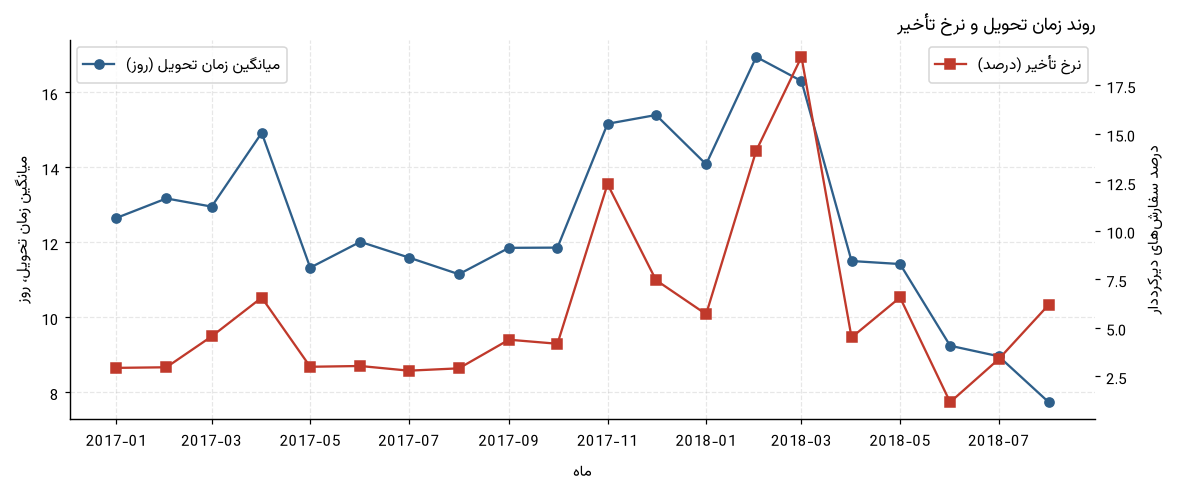

میانگین زمان تحویل سه ماه اول: 12.9 روز | سه ماه آخر: 8.6 روز
نرخ تأخیر سه ماه اول: 3.48% | سه ماه آخر: 3.58%


In [26]:
# --- ۹.۴ روند ماهانه زمان تحویل و نرخ تأخیر ---
monthly_delivery = (delivered.groupby("purchase_ym")
                    .agg(میانگین_روز=("delivery_days", "mean"),
                         نرخ_تأخیر_درصد=("delivery_class", lambda series: (series == "late").mean() * 100))
                    .reset_index())
monthly_delivery["ماه"] = pd.to_datetime(monthly_delivery["purchase_ym"] + "-01")
trend_delivery = monthly_delivery[(monthly_delivery["purchase_ym"] >= CORE_START)
                                  & (monthly_delivery["purchase_ym"] <= CORE_END)]

fig, ax = plt.subplots(figsize=(10.8, 4.6))
ax.plot(trend_delivery["ماه"], trend_delivery["میانگین_روز"], marker="o", color=COLOR_MAIN,
        label="میانگین زمان تحویل (روز)")
ax.set_ylabel("میانگین زمان تحویل، روز")
ax2 = ax.twinx()
ax2.plot(trend_delivery["ماه"], trend_delivery["نرخ_تأخیر_درصد"], marker="s",
         color=COLOR_ACCENT, label="نرخ تأخیر (درصد)")
ax2.set_ylabel("درصد سفارش‌های دیرکرددار")
ax2.grid(False)
ax.set_title("روند زمان تحویل و نرخ تأخیر", loc="right", fontsize=12)
ax.set_xlabel("ماه")
ax.legend(loc="upper left")
ax2.legend(loc="upper right")
fig.tight_layout()
plt.show()

first_quarter = trend_delivery.head(3)
last_quarter = trend_delivery.tail(3)
print(f"میانگین زمان تحویل سه ماه اول: {first_quarter['میانگین_روز'].mean():.1f} روز"
      f" | سه ماه آخر: {last_quarter['میانگین_روز'].mean():.1f} روز")
print(f"نرخ تأخیر سه ماه اول: {first_quarter['نرخ_تأخیر_درصد'].mean():.2f}%"
      f" | سه ماه آخر: {last_quarter['نرخ_تأخیر_درصد'].mean():.2f}%")

<div dir="rtl" align="right">

**تفسیر**

- میانگین زمان تحویل حدود ۱۲٫۶ روز و میانه حدود ۱۰٫۲ روز است. اختلاف ۲٫۴ روزه میان
  این دو و چولگی مثبت نشان می‌دهد توزیع راست‌چوله است: بیشتر سفارش‌ها در محدوده ۶ تا
  ۱۶ روز می‌رسند و دنباله‌ای از سفارش‌های بسیار دیرآمده وجود دارد که میانگین را بالا
  می‌کشد. برای گزارش عملکرد، میانه تصویر واقعی‌تری از تجربه مشتری معمولی می‌دهد.
- حدود ۲۷ درصد سفارش‌ها در ۷ روز اول می‌رسند، اما ۴٫۷ درصد بیش از ۳۰ روز طول می‌کشند؛
  همین گروه کوچک است که تجربه بد می‌سازد.
- بیشتر سفارش‌ها زودتر از تاریخ تخمینی می‌رسند و تنها ۶٫۸ درصد دیرکردارند. این دیرکرد
  اما روی رضایت اثر نامتناسبی می‌گذارد (بخش بعدی).
- دیرکرد یک مشکل سراسری نیست: در چند ایالت شمال و شمال‌شرق نرخ تأخیر و میانگین زمان
  تحویل هر دو بالاتر است. تفاوت جغرافیایی، اثر مستقیم فاصله از مراکز توزیع و کیفیت
  حمل‌ونقل محلی است.
- روند ماهانه نشان می‌دهد زمان تحویل و نرخ تأخیر حرکت هم‌جهت دارند؛ ماه‌هایی که حجم
  سفارش بالا رفته، هر دو شاخص بدتر شده‌اند. یعنی ظرفیت عملیات در اوج تقاضا کشش کافی
  ندارد.

</div>

<div dir="rtl" align="right">

## بخش ۱۰ — تحلیل رضایت مشتریان

امتیاز نظرها بین ۱ تا ۵ است. چون چند نظر برای یک سفارش وجود دارد، پیش از محاسبه
میانگین، نظرات را در سطح سفارش یکتا کردیم.

</div>

,تعداد,درصد
امتیاز,,
1,11363,11.52
2,3131,3.17
3,8133,8.24
4,19038,19.29
5,57008,57.77


,مقدار
سفارش دارای نظر,"98,673.00"
میانگین امتیاز,4.09
میانه امتیاز,5.00
درصد امتیاز ۴ و ۵,77.07
درصد امتیاز ۱ و ۲,14.69
درصد امتیاز ۱,11.52


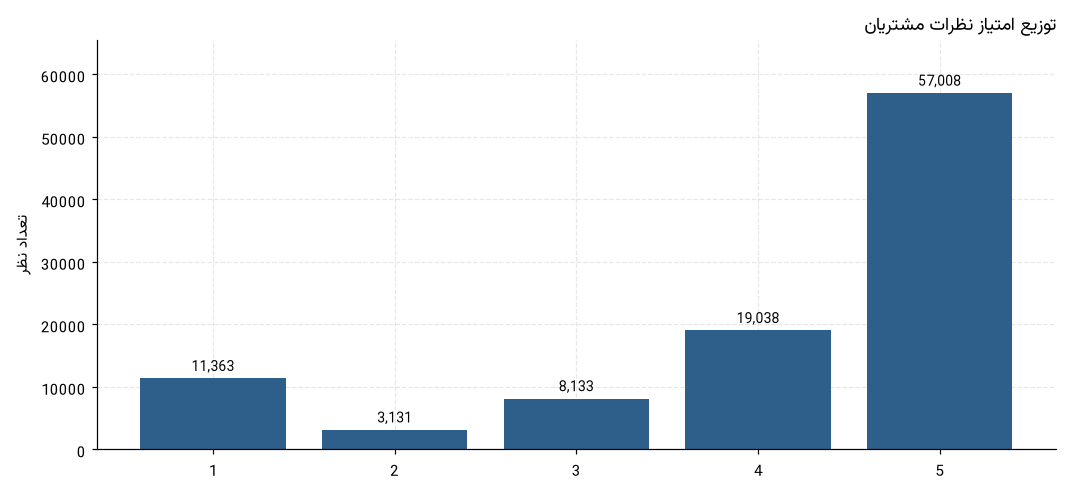

In [27]:
# --- ۱۰.۱ توزیع امتیازها و شاخص‌های کلی ---
scored = orders[orders["review_score"].notna()].copy()
overall_score = scored["review_score"].mean()
score_counts = scored["review_score"].value_counts().sort_index()
score_table = pd.DataFrame({
    "امتیاز": score_counts.index.astype(int),
    "تعداد": score_counts.values,
    "درصد": (score_counts.values / len(scored) * 100).round(2),
}).set_index("امتیاز")
display(score_table)

score_kpi = pd.Series({
    "سفارش دارای نظر": len(scored),
    "میانگین امتیاز": round(overall_score, 4),
    "میانه امتیاز": float(scored["review_score"].median()),
    "درصد امتیاز ۴ و ۵": round((scored["review_score"] >= 4).mean() * 100, 2),
    "درصد امتیاز ۱ و ۲": round((scored["review_score"] <= 2).mean() * 100, 2),
    "درصد امتیاز ۱": round((scored["review_score"] == 1).mean() * 100, 2),
}, name="مقدار")
display(score_kpi.to_frame())

bars(score_table["تعداد"], "توزیع امتیاز نظرات مشتریان", "تعداد نظر")

دسته‌بندی با حداقل ۳۰ نظر: 63 از 73


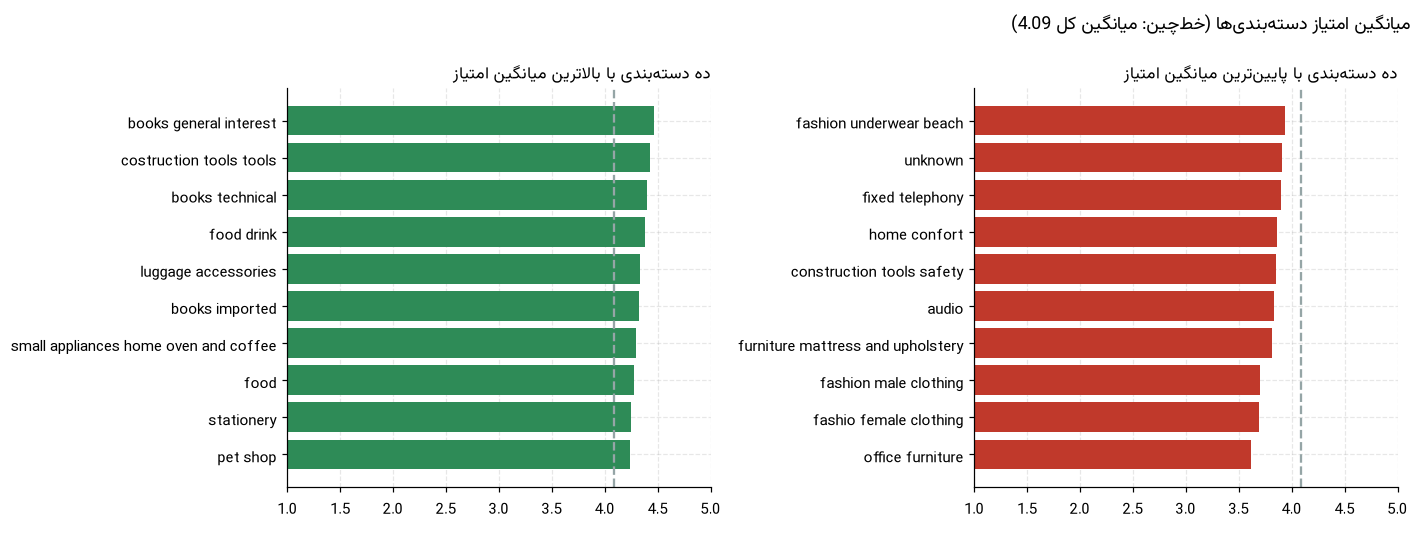

کمترین تعداد نظر در این فهرست: 38


,نظر,میانگین_امتیاز
category_label,,
pet_shop,1701,4.24
stationery,2295,4.25
food,445,4.28
office_furniture,1263,3.62
fashio_female_clothing,39,3.69
fashion_male_clothing,111,3.70


نمونه دسته‌بندی‌هایی با کمتر از ۳۰ نظر که در فهرست بالا و پایین قرار می‌گرفتند:


,نظر,میانگین_امتیاز
category_label,,
flowers,28,4.39
fashion_childrens_clothes,8,4.50
cds_dvds_musicals,12,4.67
security_and_services,2,2.50
pc_gamer,8,3.12
portateis_cozinha_e_preparadores_de_alimentos,14,3.43


In [28]:
# --- ۱۰.۲ رضایت به تفکیک دسته‌بندی ---
cat_sat = (order_category.groupby("category_label")
           .agg(نظر=("review_score", "count"),
                میانگین_امتیاز=("review_score", "mean"),
                مبلغ_فروش=("revenue", "sum")))
cat_sat = cat_sat[cat_sat["نظر"] >= 30]
print("دسته‌بندی با حداقل ۳۰ نظر:", len(cat_sat), "از", category.shape[0])

best = cat_sat.nlargest(10, "میانگین_امتیاز").sort_values("میانگین_امتیاز")
worst = cat_sat.nsmallest(10, "میانگین_امتیاز").sort_values("میانگین_امتیاز")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.9), sharex=True)
for axis, frame, color, title in [
    (axes[0], best, "#2E8B57", "ده دسته‌بندی با بالاترین میانگین امتیاز"),
    (axes[1], worst, COLOR_ACCENT, "ده دسته‌بندی با پایین‌ترین میانگین امتیاز"),
]:
    axis.barh([name.replace("_", " ") for name in frame.index], frame["میانگین_امتیاز"], color=color)
    axis.axvline(overall_score, color=COLOR_MUTED, linestyle="--")
    axis.set_title(title, loc="right", fontsize=11)
    axis.set_xlim(1, 5)
    axis.margins(x=0.16)
fig.suptitle(f"میانگین امتیاز دسته‌بندی‌ها (خط‌چین: میانگین کل {overall_score:.2f})",
             x=0.99, ha="right", fontsize=12)
fig.tight_layout()
plt.show()

print("کمترین تعداد نظر در این فهرست:", int(min(best["نظر"].min(), worst["نظر"].min())))
display(pd.concat([best.head(3), worst.head(3)])[["نظر", "میانگین_امتیاز"]].round(2))

low_volume = (order_category.groupby("category_label")
              .agg(نظر=("review_score", "count"), میانگین_امتیاز=("review_score", "mean")))
low_volume = low_volume[low_volume["نظر"] < 30].sort_values("میانگین_امتیاز")
print("نمونه دسته‌بندی‌هایی با کمتر از ۳۰ نظر که در فهرست بالا و پایین قرار می‌گرفتند:")
display(pd.concat([low_volume.tail(3), low_volume.head(3)]).round(2))

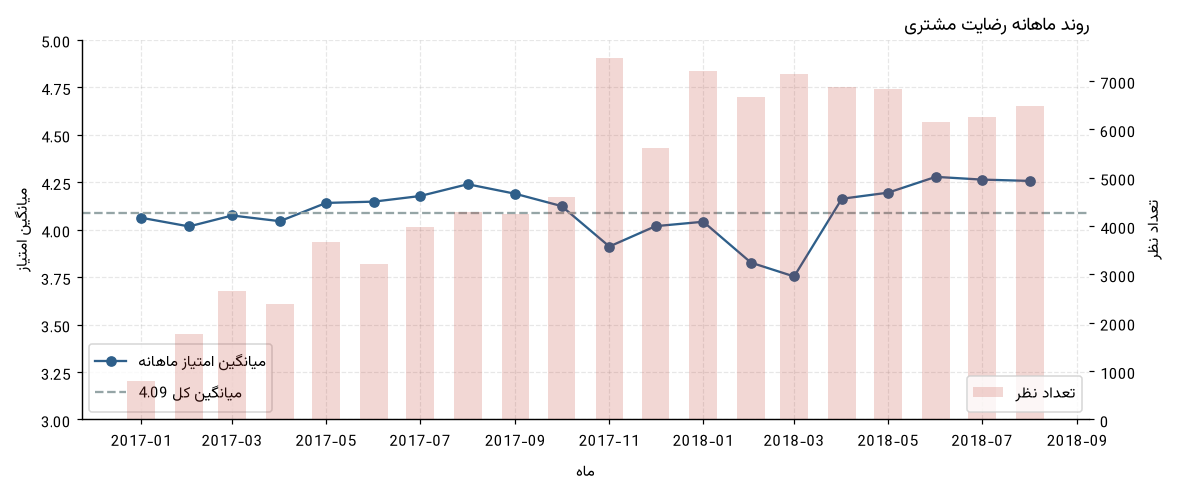

ده دسته‌بندی پرفروش و میانگین امتیازشان:


,نظر,میانگین_امتیاز,مبلغ_فروش
category_label,,,
health_beauty,8771,4.18,"1,258,681.34"
watches_gifts,5576,4.07,"1,205,005.68"
bed_bath_table,9313,3.97,"1,036,988.68"
sports_leisure,7669,4.17,"988,048.97"
computers_accessories,6649,4.03,"911,954.32"
furniture_decor,6398,4.01,"729,762.49"
cool_stuff,3599,4.17,"635,290.85"
housewares,5843,4.14,"632,248.66"
auto,3877,4.09,"592,720.11"


از این ده مورد، 4 دسته‌بندی زیر میانگین کل هستند:


,میانگین_امتیاز,مبلغ_فروش
category_label,,
watches_gifts,4.07,"1,205,005.68"
bed_bath_table,3.97,"1,036,988.68"
computers_accessories,4.03,"911,954.32"
furniture_decor,4.01,"729,762.49"


In [29]:
# --- ۱۰.۳ روند زمانی رضایت و مقایسه با فروش ---
monthly_score = (scored.groupby("purchase_ym")
                 .agg(میانگین_امتیاز=("review_score", "mean"), نظر=("review_score", "size"))
                 .reset_index())
monthly_score["ماه"] = pd.to_datetime(monthly_score["purchase_ym"] + "-01")
score_trend = monthly_score[(monthly_score["purchase_ym"] >= CORE_START)
                            & (monthly_score["purchase_ym"] <= CORE_END)]

fig, ax = plt.subplots(figsize=(10.8, 4.6))
ax.plot(score_trend["ماه"], score_trend["میانگین_امتیاز"], marker="o", color=COLOR_MAIN,
        label="میانگین امتیاز ماهانه")
ax.axhline(overall_score, color=COLOR_MUTED, linestyle="--", label=f"میانگین کل {overall_score:.2f}")
ax.set_ylim(3, 5)
ax.set_ylabel("میانگین امتیاز")
ax.set_xlabel("ماه")
ax2 = ax.twinx()
ax2.bar(score_trend["ماه"], score_trend["نظر"], width=18, alpha=.2, color=COLOR_ACCENT,
        label="تعداد نظر")
ax2.set_ylabel("تعداد نظر")
ax2.grid(False)
ax.set_title("روند ماهانه رضایت مشتری", loc="right", fontsize=12)
ax.legend(loc="lower left")
ax2.legend(loc="lower right")
fig.tight_layout()
plt.show()

rev_score = cat_sat.copy()
rev_score["رتبه_مبلغ"] = rev_score["مبلغ_فروش"].rank(ascending=False, method="min").astype(int)
high_revenue = rev_score[rev_score["رتبه_مبلغ"] <= 10].sort_values("مبلغ_فروش", ascending=False)
risky = high_revenue[high_revenue["میانگین_امتیاز"] < overall_score]
print("ده دسته‌بندی پرفروش و میانگین امتیازشان:")
display(high_revenue[["نظر", "میانگین_امتیاز", "مبلغ_فروش"]].round(2))
print(f"از این ده مورد، {len(risky)} دسته‌بندی زیر میانگین کل هستند:")
display(risky[["میانگین_امتیاز", "مبلغ_فروش"]].round(2))

<div dir="rtl" align="right">

**تفسیر**

- توزیع امتیازها دوقطبی است: حدود ۵۸ درصد امتیاز ۵ و در همان حال ۱۱٫۵ درصد امتیاز ۱.
  میانگین ۴٫۰۹ و میانه ۵ است، اما این میانگین بالا نباید تصویر را خوش‌بینانه کند؛
  تجربه بخشی از مشتریان واقعاً بد بوده است.
- ۷۷ درصد نظرات ۴ یا ۵ و حدود ۱۵ درصد ۱ یا ۲ هستند. برای پایش تجربه مشتری، درصد
  امتیازهای پایین شاخص حساس‌تری از میانگین است، چون میانگین با حجم امتیازهای ۵ پنهان
  می‌شود.
- روند ماهانه نسبتاً پایدار است و نوسان شدیدی ندارد؛ افت‌های مقطعی بیشتر در ماه‌های
  پرحجم دیده می‌شود که با افزایش زمان تحویل هم‌زمان است.
- در میان ده دسته‌بندی پرفروش، چند مورد میانگین امتیاز پایین‌تر از کل دارند. این‌ها
  دقیقاً همان جایی هستند که بهبود کیفیت، بیشترین اثر مالی را دارد.
- دسته‌بندی‌هایی که در فهرست بدترین‌ها هستند اما تعداد نظر کمی دارند، نباید با همین
  میانگین قضاوت شوند؛ به همین دلیل حداقل ۳۰ نظر گذاشتیم و تعداد نظر را کنار نتیجه
  نگه داشتیم.

</div>

<div dir="rtl" align="right">

## بخش ۱۱ — ارتباط تأخیر در تحویل و رضایت مشتری

فرضیه تیم تجربه مشتری این است که تأخیر، رضایت را کاهش می‌دهد. برای آزمون آن، امتیاز
سفارش‌های به‌موقع و دیرکردار را مقایسه می‌کنیم و بعد شدت تأخیر را هم بررسی می‌کنیم.

</div>

,سفارش,میانگین_امتیاز,سهم_از_نظرات_درصد
به‌موقع یا زودتر,89443,4.29,93.34
با تأخیر,6381,2.27,6.66


اختلاف میانگین امتیاز: 2.02


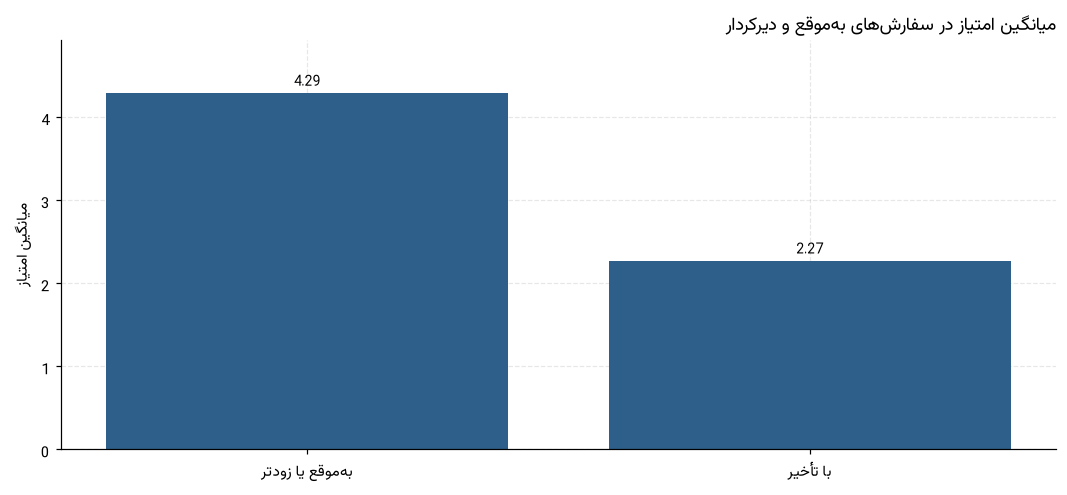

In [30]:
# --- ۱۱.۱ مقایسه دو گروه ---
# فقط سفارش‌های تحویل‌شده: شش سفارش با وضعیت غیر از delivered هم تاریخ تحویل و
# نظر دارند و اگر فیلتر نشوند، گروه‌بندی «به‌موقع/دیرکردار» شش ردیف اضافه می‌گیرد
# و با جدول‌های خط لوله گزارش یکی نمی‌شود.
reviewed = scored[scored["is_delivered"] & scored["delivery_class"].notna()].copy()
reviewed["گروه"] = np.where(reviewed["delivery_class"] == "late", "late", "on_time")

comparison = (reviewed.groupby("گروه")
              .agg(سفارش=("review_score", "size"), میانگین_امتیاز=("review_score", "mean"))
              .reindex(["on_time", "late"]))
comparison.index = ["به‌موقع یا زودتر", "با تأخیر"]
comparison["سهم_از_نظرات_درصد"] = (comparison["سفارش"] / len(reviewed) * 100).round(2)
display(comparison.round(3))

score_gap = (comparison.loc["به‌موقع یا زودتر", "میانگین_امتیاز"]
             - comparison.loc["با تأخیر", "میانگین_امتیاز"])
print(f"اختلاف میانگین امتیاز: {score_gap:.2f}")
bars(comparison["میانگین_امتیاز"], "میانگین امتیاز در سفارش‌های به‌موقع و دیرکردار",
     "میانگین امتیاز", fmt="{:.2f}")

,سفارش,میانگین_امتیاز
به‌موقع یا زودتر,89443,4.29
۱ تا ۳ روز,1852,3.29
۴ تا ۷ روز,1748,2.10
بیش از ۷ روز,2781,1.70


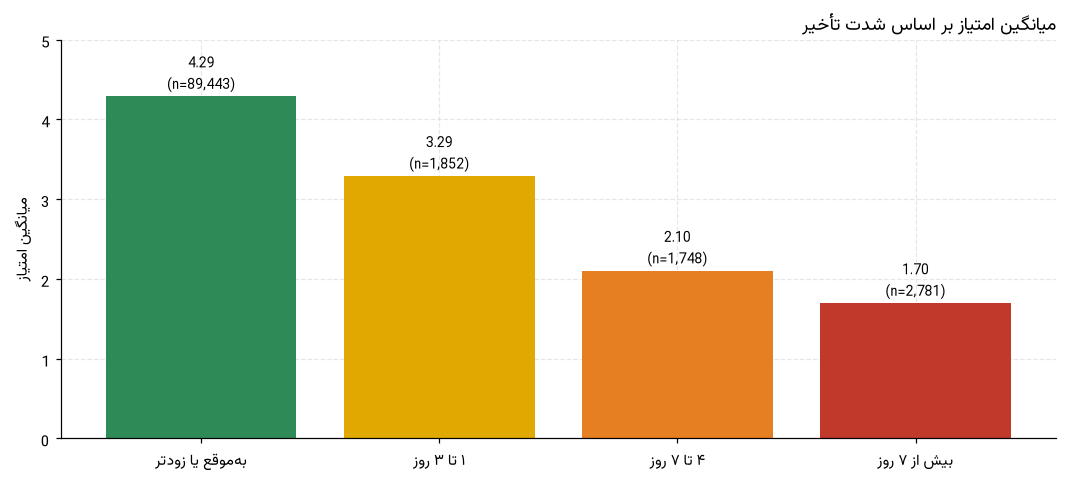

افت امتیاز از به‌موقع به بیش از ۷ روز: 2.59


In [31]:
# --- ۱۱.۲ شدت تأخیر ---
bucket_satisfaction = (reviewed.groupby("delay_bucket")
                       .agg(سفارش=("review_score", "size"), میانگین_امتیاز=("review_score", "mean"))
                       .reindex(BUCKET_ORDER))
bucket_satisfaction.index = [BUCKET_FA[key] for key in bucket_satisfaction.index]
display(bucket_satisfaction.round(3))

fig, ax = plt.subplots(figsize=(9.8, 4.5))
positions = range(len(bucket_satisfaction))
ax.bar(positions, bucket_satisfaction["میانگین_امتیاز"],
       color=["#2E8B57", "#E0A800", "#E67E22", COLOR_ACCENT])
for position, (count, value) in enumerate(zip(bucket_satisfaction["سفارش"],
                                             bucket_satisfaction["میانگین_امتیاز"])):
    ax.text(position, value, f"{value:.2f}\n(n={int(count):,})", ha="center", va="bottom", fontsize=9)
ax.set_xticks(list(positions))
ax.set_xticklabels(bucket_satisfaction.index)
ax.set_ylim(0, 5)
ax.set_title("میانگین امتیاز بر اساس شدت تأخیر", loc="right", fontsize=12)
ax.set_ylabel("میانگین امتیاز")
ax.margins(y=0.18)
fig.tight_layout()
plt.show()

print("افت امتیاز از به‌موقع به بیش از ۷ روز:",
      f"{bucket_satisfaction.iloc[0, 1] - bucket_satisfaction.iloc[-1, 1]:.2f}")

دسته‌بندی با حداقل ۳۰ سفارش در هر گروه: 29


,ن_با_تأخیر,ن_به‌موقع,امتیاز_با_تأخیر,امتیاز_به‌موقع,اختلاف
category_label,,,,,
bed_bath_table,668.00,"8,509.00",2.23,4.14,1.91
health_beauty,633.00,"7,968.00",2.34,4.38,2.04
sports_leisure,487.00,"6,998.00",2.17,4.37,2.20
furniture_decor,440.00,"5,820.00",2.33,4.19,1.86
computers_accessories,407.00,"6,091.00",2.27,4.20,1.93
watches_gifts,395.00,"5,057.00",2.20,4.27,2.07
housewares,300.00,"5,409.00",2.26,4.30,2.04
telephony,287.00,"3,782.00",2.43,4.17,1.74


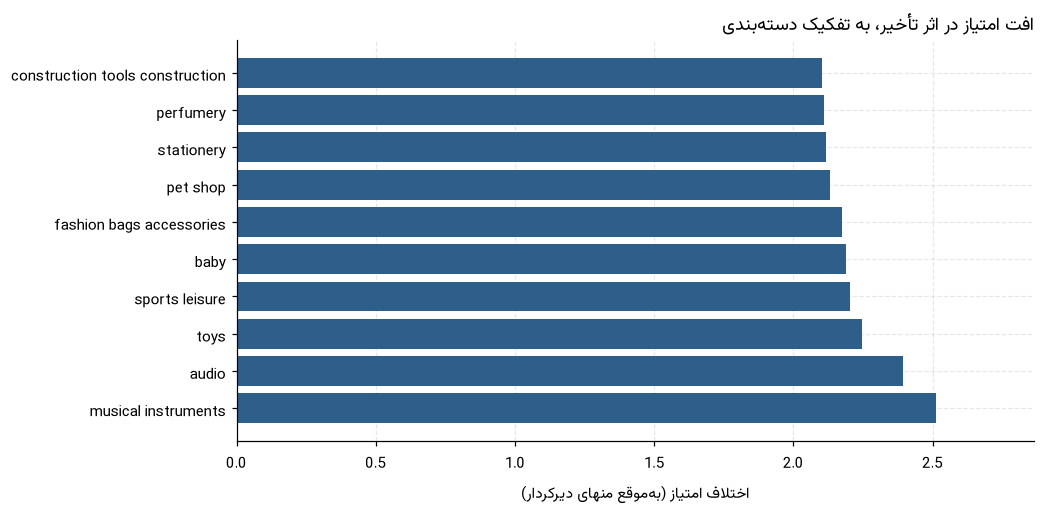

همه دسته‌بندی‌ها افت امتیاز دارند؟ True
بیشترین افت: 2.51 در musical_instruments


In [32]:
# --- ۱۱.۳ تفاوت میان دسته‌بندی‌ها ---
reviewed_categories = order_category[order_category["review_score"].notna()
                                    & order_category["is_delivered"]
                                    & order_category["delivery_class"].notna()].copy()
reviewed_categories["گروه"] = np.where(reviewed_categories["delivery_class"] == "late", "late", "on_time")
pivot = reviewed_categories.pivot_table(index="category_label", columns="گروه",
                                        values="review_score", aggfunc=["size", "mean"])
pivot.columns = [f"{stat}_{group}" for stat, group in pivot.columns]
pivot = pivot.rename(columns={"size_on_time": "ن_به‌موقع", "size_late": "ن_با_تأخیر",
                              "mean_on_time": "امتیاز_به‌موقع", "mean_late": "امتیاز_با_تأخیر"})
pivot = pivot.dropna()
pivot = pivot[(pivot["ن_به‌موقع"] >= 30) & (pivot["ن_با_تأخیر"] >= 30)]
pivot["اختلاف"] = pivot["امتیاز_به‌موقع"] - pivot["امتیاز_با_تأخیر"]
print("دسته‌بندی با حداقل ۳۰ سفارش در هر گروه:", len(pivot))
display(pivot.sort_values("ن_با_تأخیر", ascending=False).head(8).round(2))

fig, ax = plt.subplots(figsize=(9.6, 4.8))
plotted = pivot.sort_values("اختلاف", ascending=False).head(10)
ax.barh([name.replace("_", " ") for name in plotted.index], plotted["اختلاف"], color=COLOR_MAIN)
ax.set_title("افت امتیاز در اثر تأخیر، به تفکیک دسته‌بندی", loc="right", fontsize=12)
ax.set_xlabel("اختلاف امتیاز (به‌موقع منهای دیرکردار)")
ax.margins(x=0.14)
fig.tight_layout()
plt.show()
print("همه دسته‌بندی‌ها افت امتیاز دارند؟", bool((pivot["اختلاف"] > 0).all()))
print("بیشترین افت:", f"{pivot['اختلاف'].max():.2f}", "در", pivot["اختلاف"].idxmax())

<div dir="rtl" align="right">

**تفسیر تحلیلی**

- اختلاف امتیاز دو گروه حدود ۲ واحد از ۵ است (۴٫۲۹ در برابر ۲٫۲۷)؛ این بزرگ‌ترین
  شکافی است که در کل پروژه دیدیم و با نمونه‌ای چند ده‌هزارتایی پشتیبانی می‌شود. فرضیه
  تیم تجربه مشتری با داده سازگار است.
- رابطه با شدت تأخیر یکنوا نیست: در بازه ۱ تا ۳ روز افت ملایم است، از ۴ روز به بعد
  افت تندتر می‌شود و در بیش از ۷ روز به کمترین مقدار می‌رسد. یعنی «کمی دیر رسیدن»
  تقریباً بخشوده می‌شود، اما «دیر رسیدن طولانی» نه.
- در همه دسته‌بندی‌هایی که نمونه کافی دارند، امتیاز گروه دیرکردار پایین‌تر است؛ پس این
  الگو به یک محصول یا یک فروشنده خاص محدود نیست.
- **محدودیت مهم:** این یک تحلیل مشاهده‌ای است. تأخیر با عوامل دیگری مثل ایالت دور،
  فروشنده ضعیف یا انتظار بالا هم‌بسته است و ممکن است بخشی از افت امتیاز به همان عوامل
  مربوط باشد. برای اثبات علیت به آزمون کنترل‌شده یا تحلیل با کنترل متغیرهای همراه
  نیاز است؛ داده فعلی فقط هم‌بستگی قوی نشان می‌دهد.

</div>

<div dir="rtl" align="right">

## بخش ۱۲ — تحلیل عملکرد فروشندگان

پرسش مدیریت: فروش چقدر متمرکز است و آیا فروشندگان بزرگ، مشتریان را هم راضی نگه
می‌دارند.

</div>

,مقدار
فروشنده یکتا,"3,095.00"
ایالت دارای فروشنده,23.00
میانه اقلام هر فروشنده,8.00
میانه مبلغ فروش هر فروشنده (BRL),821.48
فروشنده با حداقل ۳۰ نظر,628.00


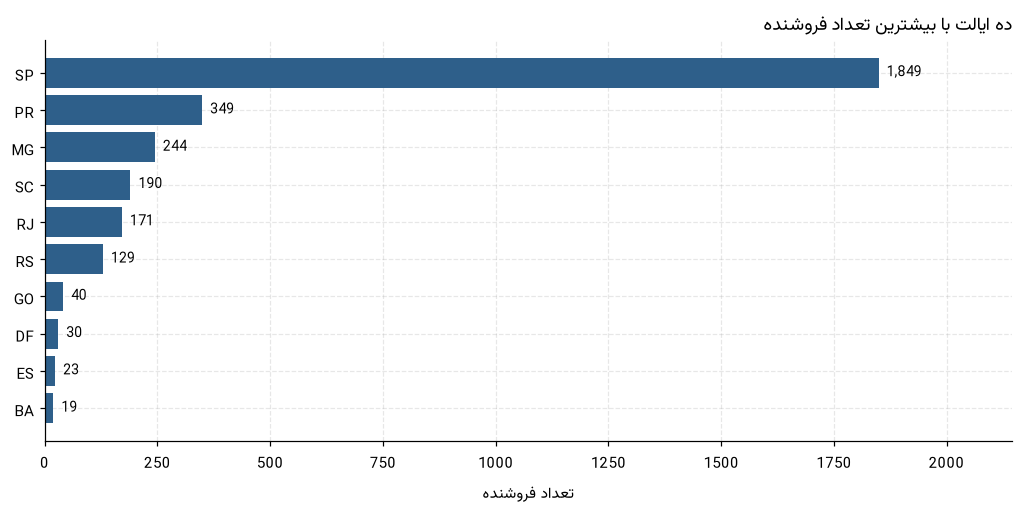

In [33]:
# --- ۱۲.۱ تعداد و پراکندگی فروشندگان ---
seller_state = raw["sellers"].set_index("seller_id")["seller_state"]
seller_perf = (order_seller.groupby("seller_id")
               .agg(اقلام=("n_items", "sum"),
                    مبلغ_فروش=("revenue", "sum"),
                    نظر=("review_score", "count"),
                    میانگین_امتیاز=("review_score", "mean")))
seller_perf["ایالت"] = seller_state.reindex(seller_perf.index)

seller_facts = pd.Series({
    "فروشنده یکتا": len(seller_perf),
    "ایالت دارای فروشنده": seller_perf["ایالت"].nunique(),
    "میانه اقلام هر فروشنده": float(seller_perf["اقلام"].median()),
    "میانه مبلغ فروش هر فروشنده (BRL)": float(seller_perf["مبلغ_فروش"].median()),
    "فروشنده با حداقل ۳۰ نظر": int((seller_perf["نظر"] >= 30).sum()),
}, name="مقدار")
display(seller_facts.to_frame())

barh(seller_perf["ایالت"].value_counts().head(10), "ده ایالت با بیشترین تعداد فروشنده", "تعداد فروشنده")

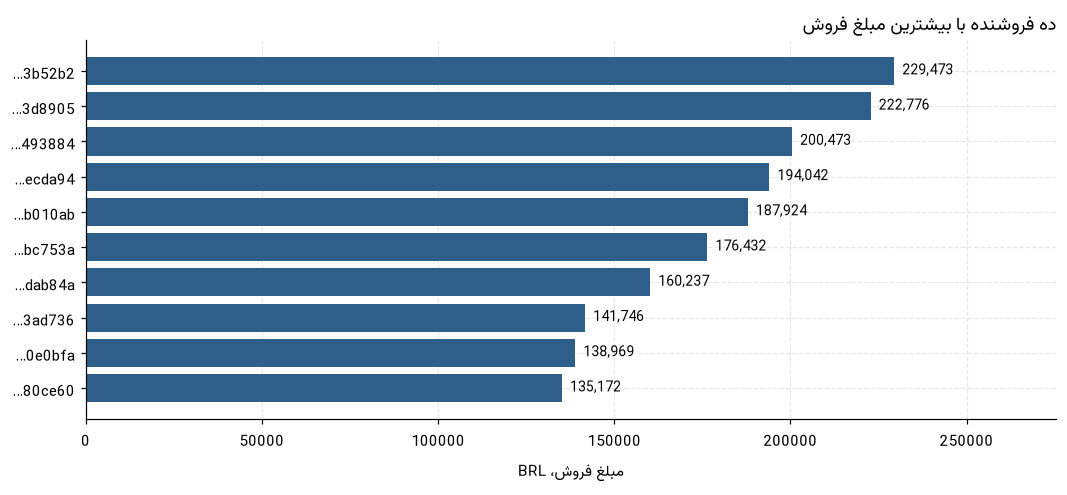

سهم ده فروشنده اول از مبلغ فروش: 13.15%
سهم ده فروشنده اول از تعداد اقلام: 10.20%
میانه سهم هر فروشنده از فروش: 0.0060%
فروشندگانی که رتبه اقلام و رتبه مبلغشان فاصله زیادی دارد:


,اقلام,مبلغ_فروش,میانگین_امتیاز,رتبه_اقلام,رتبه_مبلغ,اختلاف_رتبه
seller_id,,,,,,
80ceebb4ee9b31afb6c6a916a574a1e2,1,"6,729.00",NaN,2587,458,2129
ee27a8f15b1dded4d213a468ba4eb391,1,"6,499.00",5.00,2587,474,2113
585175ec331ea177fa47199e39a6170a,1,"3,549.00",5.00,2587,749,1838
abe021b01ba992245271b9aa422032df,2,"6,720.00",3.50,2259,459,1800
e908c0f3646e8b60375734a350d95d71,1,"2,951.00",4.00,2587,824,1763


In [34]:
# --- ۱۲.۲ فروش فروشندگان ---
top_sellers = seller_perf.nlargest(10, "مبلغ_فروش").sort_values("مبلغ_فروش")
fig, ax = plt.subplots(figsize=(9.8, 4.6))
ax.barh([f"…{seller[-6:]}" for seller in top_sellers.index], top_sellers["مبلغ_فروش"], color=COLOR_MAIN)
for row, value in enumerate(top_sellers["مبلغ_فروش"]):
    ax.text(value, row, f"  {value:,.0f}", va="center", fontsize=9)
ax.set_title("ده فروشنده با بیشترین مبلغ فروش", loc="right", fontsize=12)
ax.set_xlabel("مبلغ فروش، BRL")
ax.margins(x=0.2)
fig.tight_layout()
plt.show()

top10_revenue = top_sellers["مبلغ_فروش"].sum()
total_revenue = seller_perf["مبلغ_فروش"].sum()
print(f"سهم ده فروشنده اول از مبلغ فروش: {top10_revenue / total_revenue * 100:.2f}%")
print(f"سهم ده فروشنده اول از تعداد اقلام: {top_sellers['اقلام'].sum() / seller_perf['اقلام'].sum() * 100:.2f}%")
print(f"میانه سهم هر فروشنده از فروش: {seller_perf['مبلغ_فروش'].median() / total_revenue * 100:.4f}%")

seller_perf["رتبه_اقلام"] = seller_perf["اقلام"].rank(ascending=False, method="min").astype(int)
seller_perf["رتبه_مبلغ"] = seller_perf["مبلغ_فروش"].rank(ascending=False, method="min").astype(int)
seller_perf["اختلاف_رتبه"] = seller_perf["رتبه_اقلام"] - seller_perf["رتبه_مبلغ"]
movers = seller_perf.reindex(seller_perf["اختلاف_رتبه"].abs().nlargest(5).index)
print("فروشندگانی که رتبه اقلام و رتبه مبلغشان فاصله زیادی دارد:")
display(movers[["اقلام", "مبلغ_فروش", "میانگین_امتیاز", "رتبه_اقلام", "رتبه_مبلغ", "اختلاف_رتبه"]].round(2))

فروشنده با حداقل ۳۰ نظر: 628
آستانه فروش (چارک سوم): 15,388.43 BRL
فروشنده پرفروش با امتیاز زیر میانگین: 64


,اقلام,مبلغ_فروش,نظر,میانگین_امتیاز
seller_id,,,,
4a3ca9315b744ce9f8e9374361493884,1987,"200,472.92",1785,3.83
7c67e1448b00f6e969d365cea6b010ab,1364,"187,923.89",976,3.49
1025f0e2d44d7041d6cf58b6550e0bfa,1428,"138,968.55",907,3.99
6560211a19b47992c3666cc44a7e94c0,2033,"123,304.83",1838,3.93
7d13fca15225358621be4086e1eb0964,578,"113,628.97",561,4.02


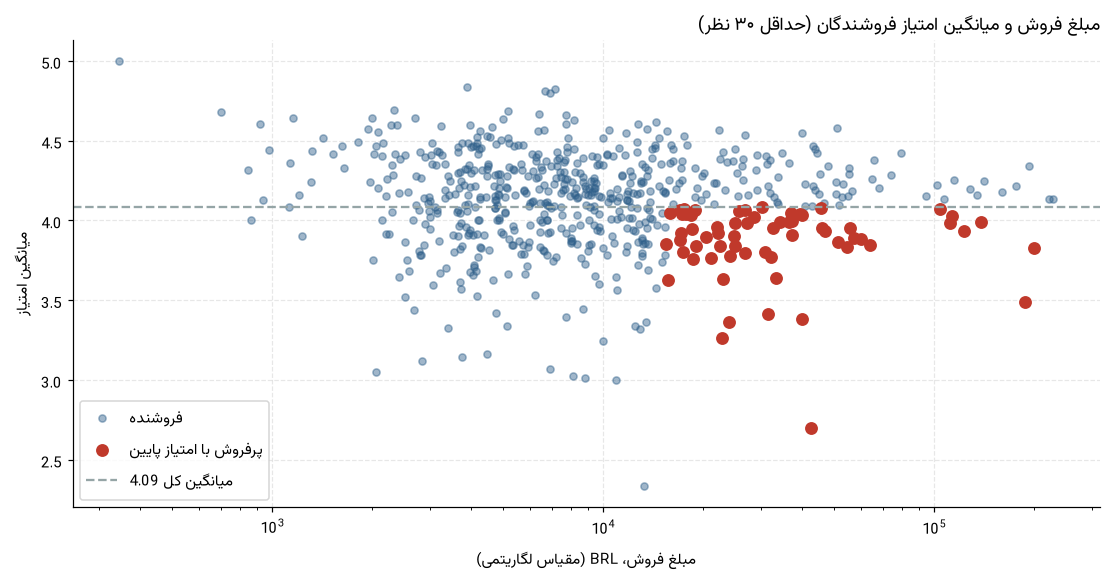

In [35]:
# --- ۱۲.۳ فروش در برابر رضایت ---
scored_sellers = seller_perf[(seller_perf["نظر"] >= 30) & seller_perf["میانگین_امتیاز"].notna()].copy()
threshold = scored_sellers["مبلغ_فروش"].quantile(0.75)
scored_sellers["پرچم"] = ((scored_sellers["مبلغ_فروش"] >= threshold)
                          & (scored_sellers["میانگین_امتیاز"] < overall_score))
flagged = scored_sellers[scored_sellers["پرچم"]].sort_values("مبلغ_فروش", ascending=False)

print(f"فروشنده با حداقل ۳۰ نظر: {len(scored_sellers)}")
print(f"آستانه فروش (چارک سوم): {threshold:,.2f} BRL")
print(f"فروشنده پرفروش با امتیاز زیر میانگین: {len(flagged)}")
display(flagged[["اقلام", "مبلغ_فروش", "نظر", "میانگین_امتیاز"]].head(5).round(2))

fig, ax = plt.subplots(figsize=(10.2, 5.4))
ax.scatter(scored_sellers["مبلغ_فروش"].clip(lower=1), scored_sellers["میانگین_امتیاز"],
           s=22, alpha=.45, color=COLOR_MAIN, label="فروشنده")
ax.scatter(flagged["مبلغ_فروش"], flagged["میانگین_امتیاز"], s=55, color=COLOR_ACCENT,
           label="پرفروش با امتیاز پایین")
ax.axhline(overall_score, color=COLOR_MUTED, linestyle="--", label=f"میانگین کل {overall_score:.2f}")
ax.set_xscale("log")
ax.set_title("مبلغ فروش و میانگین امتیاز فروشندگان (حداقل ۳۰ نظر)", loc="right", fontsize=12)
ax.set_xlabel("مبلغ فروش، BRL (مقیاس لگاریتمی)")
ax.set_ylabel("میانگین امتیاز")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

<div dir="rtl" align="right">

**تفسیر**

- ۳٬۰۹۵ فروشنده در ۲۳ ایالت فعال‌اند، اما میانه فروش هر فروشنده حدود ۸۲۱ دلار است؛
  یعنی توده فروشندگان بسیار کوچک‌اند و بخش زیادی از فروش به گروه کوچکی از فروشندگان
  بزرگ می‌رسد. ده فروشنده اول حدود ۱۳ درصد فروش و ۱۰ درصد اقلام را در اختیار دارند.
- رتبه‌بندی بر اساس تعداد اقلام با رتبه‌بندی بر اساس مبلغ یکسان نیست؛ برخی فروشندگان
  با حجم بالا، قیمت واحد پایین دارند و در مبلغ جایگاه پایین‌تری می‌گیرند.
- در نمودار فروش-امتیاز، بیشتر فروشندگان بزرگ در محدوده امتیاز بالا هستند؛ اما گروهی
  هم هستند که فروش بالا و امتیاز زیر میانگین دارند. تعداد نظر این گروه را کنار نتیجه
  آوردیم تا مقایسه بر پایه نمونه کوچک انجام نشود.
- فروشندگانی که در ناحیه پرچم قرار می‌گیرند، نامزد بررسی کیفیت بسته‌بندی و زمان ارسال
  هستند؛ چون هر امتیاز پایین آن‌ها روی برند پلتفرم هم اثر می‌گذارد.

</div>

<div dir="rtl" align="right">

## بخش ۱۳ — تحلیل‌های ترکیبی

در این بخش چند جدول را هم‌زمان به کار می‌بریم تا سؤال‌هایی را پاسخ دهیم که با یک جدول
قابل پاسخ نیستند. چهار تحلیل آمده است؛ تحلیل پرداخت-اقساط در بخش ۸ و تحلیل
فروشنده-رضایت در بخش ۱۲ انجام شد.

</div>

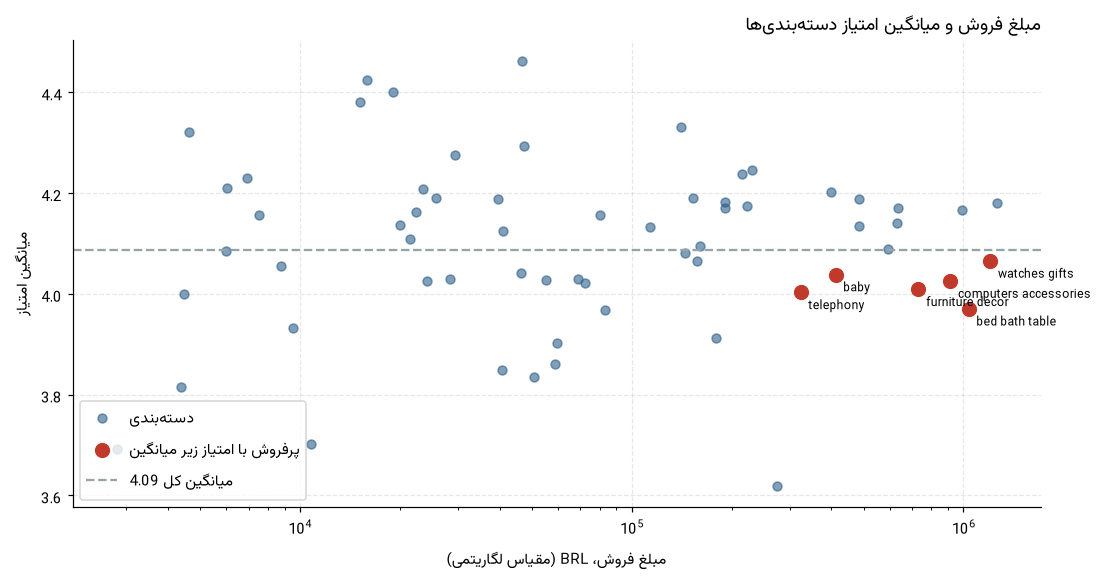

دسته‌بندی در چارک بالای فروش: 16 | از این تعداد، 7 مورد امتیاز زیر میانگین دارند


,category_label,مبلغ_فروش,میانگین_امتیاز,نظر
62,watches_gifts,"1,205,005.68",4.07,5576
6,bed_bath_table,"1,036,988.68",3.97,9313
13,computers_accessories,"911,954.32",4.03,6649
33,furniture_decor,"729,762.49",4.01,6398
5,baby,"411,764.89",4.04,2861
59,telephony,"323,667.53",4.00,4168


In [36]:
# --- ۱۳.۱ دسته‌بندی‌های پرفروش با رضایت پایین ---
combined = cat_sat.reset_index().copy()
combined["پرچم"] = ((combined["مبلغ_فروش"] >= combined["مبلغ_فروش"].quantile(0.75))
                    & (combined["میانگین_امتیاز"] < overall_score))
flagged_categories = combined[combined["پرچم"]].nlargest(6, "مبلغ_فروش")

fig, ax = plt.subplots(figsize=(10.2, 5.4))
ax.scatter(combined["مبلغ_فروش"], combined["میانگین_امتیاز"], s=34, alpha=.6, color=COLOR_MAIN,
           label="دسته‌بندی")
ax.scatter(flagged_categories["مبلغ_فروش"], flagged_categories["میانگین_امتیاز"], s=80,
           color=COLOR_ACCENT, label="پرفروش با امتیاز زیر میانگین")
for _, row in flagged_categories.iterrows():
    ax.annotate(row["category_label"].replace("_", " "),
                (row["مبلغ_فروش"], row["میانگین_امتیاز"]),
                fontsize=8, textcoords="offset points", xytext=(5, -11))
ax.axhline(overall_score, color=COLOR_MUTED, linestyle="--", label=f"میانگین کل {overall_score:.2f}")
ax.set_xscale("log")
ax.set_title("مبلغ فروش و میانگین امتیاز دسته‌بندی‌ها", loc="right", fontsize=12)
ax.set_xlabel("مبلغ فروش، BRL (مقیاس لگاریتمی)")
ax.set_ylabel("میانگین امتیاز")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

print(f"دسته‌بندی در چارک بالای فروش: {int((combined['مبلغ_فروش'] >= combined['مبلغ_فروش'].quantile(0.75)).sum())} | "
      f"از این تعداد، {int(combined['پرچم'].sum())} مورد امتیاز زیر میانگین دارند")
display(flagged_categories[["category_label", "مبلغ_فروش", "میانگین_امتیاز", "نظر"]].round(2))

آستانه میانگین زمان تحویل (میانه): 18.25 روز
آستانه نرخ تأخیر (میانه): 9.65%
ایالت بدتر از میانه در هر دو شاخص: 8


,سفارش,میانگین_روز,نرخ_تأخیر_درصد
customer_state,,,
AL,397,24.54,21.41
MA,717,21.57,17.43
SE,335,21.52,15.22
PI,476,19.46,13.87
CE,1279,21.27,13.76
BA,3256,19.34,12.16
PA,946,23.77,11.21
PB,517,20.43,10.44


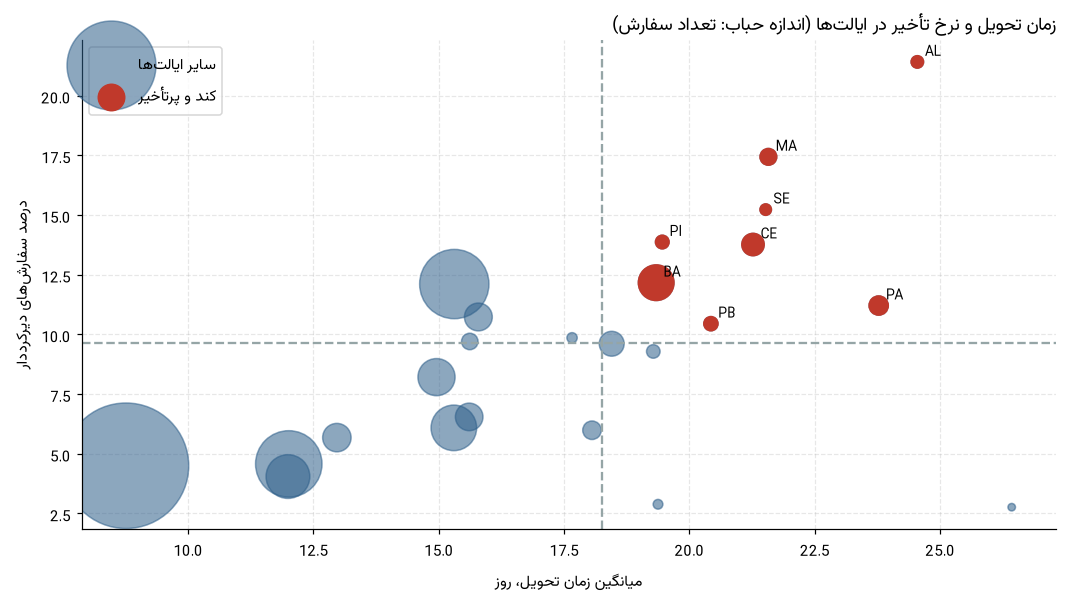

In [37]:
# --- ۱۳.۲ موقعیت جغرافیایی و عملکرد تحویل ---
geo = eligible_states.copy()
slow_median = geo["میانگین_روز"].median()
late_median = geo["نرخ_تأخیر_درصد"].median()
geo["کند"] = geo["میانگین_روز"] > slow_median
geo["تأخیر_بالا"] = geo["نرخ_تأخیر_درصد"] > late_median
geo["هر_دو"] = geo["کند"] & geo["تأخیر_بالا"]

print(f"آستانه میانگین زمان تحویل (میانه): {slow_median:.2f} روز")
print(f"آستانه نرخ تأخیر (میانه): {late_median:.2f}%")
print("ایالت بدتر از میانه در هر دو شاخص:", int(geo["هر_دو"].sum()))
display(geo[geo["هر_دو"]].sort_values("نرخ_تأخیر_درصد", ascending=False)
        [["سفارش", "میانگین_روز", "نرخ_تأخیر_درصد"]].round(2))

fig, ax = plt.subplots(figsize=(9.8, 5.6))
ax.scatter(geo["میانگین_روز"], geo["نرخ_تأخیر_درصد"], s=geo["سفارش"] / 6, alpha=.55,
           color=COLOR_MAIN, label="سایر ایالت‌ها")
ax.scatter(geo.loc[geo["هر_دو"], "میانگین_روز"], geo.loc[geo["هر_دو"], "نرخ_تأخیر_درصد"],
           s=geo.loc[geo["هر_دو"], "سفارش"] / 6, color=COLOR_ACCENT, label="کند و پرتأخیر")
ax.axvline(slow_median, color=COLOR_MUTED, linestyle="--")
ax.axhline(late_median, color=COLOR_MUTED, linestyle="--")
for state in geo[geo["هر_دو"]].index:
    ax.annotate(state, (geo.loc[state, "میانگین_روز"], geo.loc[state, "نرخ_تأخیر_درصد"]),
                fontsize=9, textcoords="offset points", xytext=(5, 4))
ax.set_title("زمان تحویل و نرخ تأخیر در ایالت‌ها (اندازه حباب: تعداد سفارش)", loc="right", fontsize=12)
ax.set_xlabel("میانگین زمان تحویل، روز")
ax.set_ylabel("درصد سفارش‌های دیرکرددار")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

,قلم,میانگین_قیمت,میانگین_امتیاز
price_decile,,,
"(0.849, 23.8]",11174,16.51,3.99
"(23.8, 34.9]",11584,28.88,4.08
"(34.9, 47.49]",10757,40.58,4.03
"(47.49, 59.0]",11306,52.62,4.02
"(59.0, 74.99]",11143,65.92,4.04
"(74.99, 95.0]",11242,84.74,3.98
"(95.0, 119.9]",11646,106.99,4.09
"(119.9, 150.0]",10596,136.06,4.03
"(150.0, 229.69]",11090,184.91,4.05


همبستگی اسپیرمن قیمت و امتیاز: 0.0060
دامنه امتیاز بین دهک‌ها: 0.11


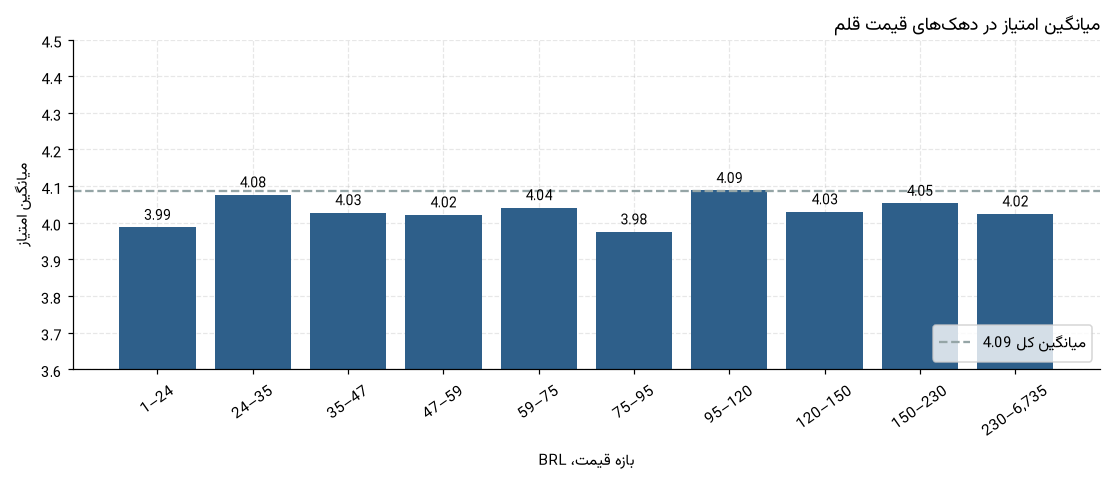

In [38]:
# --- ۱۳.۳ قیمت قلم و رضایت مشتری ---
item_scores = items.merge(orders[["order_id", "review_score"]], on="order_id", how="left")
item_scores = item_scores[item_scores["review_score"].notna()].copy()
item_scores["price_decile"] = pd.qcut(item_scores["price"], 10, duplicates="drop")
price_view = (item_scores.groupby("price_decile", observed=True)
              .agg(قلم=("price", "size"),
                   میانگین_قیمت=("price", "mean"),
                   میانگین_امتیاز=("review_score", "mean")))
price_rho = item_scores[["price", "review_score"]].corr(method="spearman").iloc[0, 1]
display(price_view.round(2))
print(f"همبستگی اسپیرمن قیمت و امتیاز: {price_rho:.4f}")
print(f"دامنه امتیاز بین دهک‌ها: {price_view['میانگین_امتیاز'].max() - price_view['میانگین_امتیاز'].min():.2f}")

fig, ax = plt.subplots(figsize=(10.2, 4.5))
positions = range(len(price_view))
ax.bar(positions, price_view["میانگین_امتیاز"], color=COLOR_MAIN)
for position, value in enumerate(price_view["میانگین_امتیاز"]):
    ax.text(position, value, f"{value:.2f}", ha="center", va="bottom", fontsize=9)
ax.axhline(overall_score, color=COLOR_MUTED, linestyle="--", label=f"میانگین کل {overall_score:.2f}")
ax.set_xticks(list(positions))
ax.set_xticklabels([f"{interval.left:,.0f}–{interval.right:,.0f}" for interval in price_view.index],
                   rotation=35)
ax.set_ylim(3.6, 4.5)
ax.set_title("میانگین امتیاز در دهک‌های قیمت قلم", loc="right", fontsize=12)
ax.set_xlabel("بازه قیمت، BRL")
ax.set_ylabel("میانگین امتیاز")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

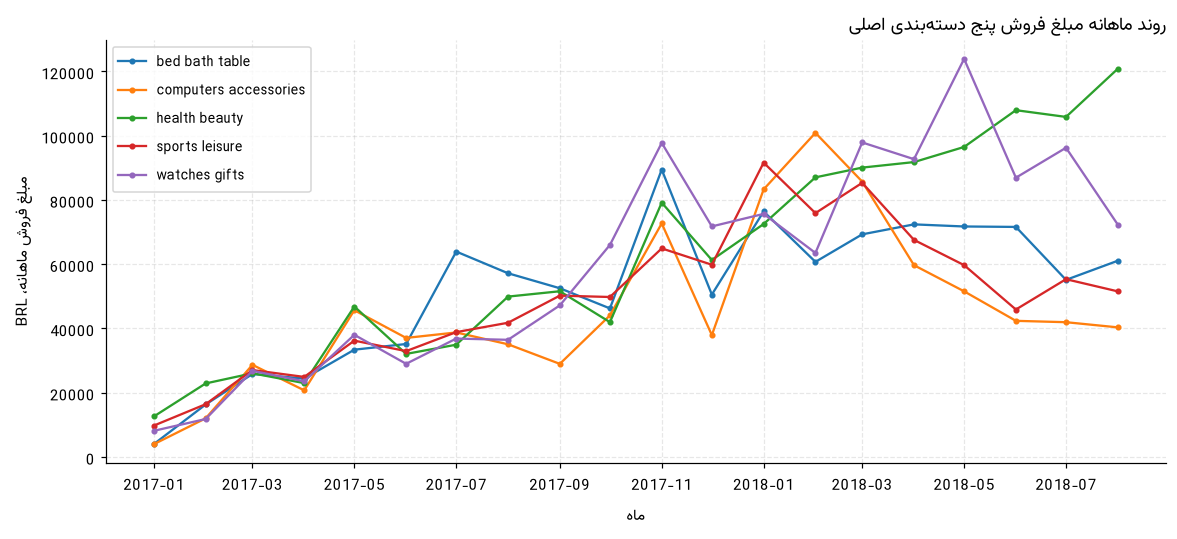

تغییر میانگین سه ماه آخر نسبت به سه ماه اول (درصد):


,تغییر
category_label,
watches_gifts,447.90
health_beauty,444.90
bed_bath_table,307.90
sports_leisure,187.50
computers_accessories,179.70


In [39]:
# --- ۱۳.۴ تغییرات فروش دسته‌بندی‌ها در طول زمان ---
top_categories = category.nlargest(5, "revenue")["category_label"].tolist()
trend_items = items[items["category_label"].isin(top_categories)].merge(
    orders[["order_id", "purchase_ym"]], on="order_id", how="left")
trend_items = trend_items[trend_items["purchase_ym"].between(CORE_START, CORE_END)]
pivot_trend = trend_items.pivot_table(index="purchase_ym", columns="category_label",
                                      values="price", aggfunc="sum").fillna(0)
pivot_trend.index = pd.to_datetime(pivot_trend.index + "-01")

fig, ax = plt.subplots(figsize=(10.8, 5.0))
for name in pivot_trend.columns:
    ax.plot(pivot_trend.index, pivot_trend[name], marker="o", markersize=3,
            label=name.replace("_", " "))
ax.set_title("روند ماهانه مبلغ فروش پنج دسته‌بندی اصلی", loc="right", fontsize=12)
ax.set_xlabel("ماه")
ax.set_ylabel("مبلغ فروش ماهانه، BRL")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()

change = (pivot_trend.iloc[-3:].mean() / pivot_trend.iloc[:3].mean() - 1) * 100
print("تغییر میانگین سه ماه آخر نسبت به سه ماه اول (درصد):")
display(change.round(1).sort_values(ascending=False).to_frame("تغییر"))

<div dir="rtl" align="right">

**تفسیر**

- تحلیل اول، دسته‌بندی‌هایی را نشان می‌دهد که مبلغ فروش بالایی دارند اما امتیازشان از
  میانگین کل پایین‌تر است. این گروه برای تیم فروش مهم است چون هر بهبود کوچک در تجربه
  آن‌ها روی حجم بزرگی از سفارش اثر می‌گذارد؛ و برای تیم تجربه مشتری مهم است چون همان
  دسته‌بندی‌ها بیشترین تعداد نظر منفی را تولید می‌کنند.
- تحلیل دوم نشان می‌دهد دیرکرد یک پدیده نقطه‌ای است: چند ایالت هم زمان تحویل طولانی
  دارند و هم نرخ تأخیر بالا، در حالی که بیشتر ایالت‌ها نزدیک میانه‌اند. این یعنی
  مداخله می‌تواند جغرافیایی و محدود باشد، نه سراسری.
- تحلیل سوم رابطه معناداری بین قیمت و امتیاز پیدا نکرد (همبستگی نزدیک صفر و دامنه
  تغییر امتیاز بین دهک‌ها حدود یک‌دهم واحد). پس «گران‌تر بودن» نه رضایت می‌آورد و نه
  از آن می‌کاهد؛ این نتیجه با شهود رایج که «کالای گران، انتظار بالاتر و امتیاز پایین‌تر»
  می‌سازد، هم‌خوان نیست و نشان می‌دهد کیفیت تحویل و تطابق کالا مهم‌تر از قیمت است.
- تحلیل چهارم: پنج دسته‌بندی اصلی هم‌جهت با کل بازار رشد کرده‌اند، اما شیب رشدشان
  یکسان نیست. دسته‌بندی‌هایی که در سه ماه آخر نسبت به سه ماه اول رشد کمتری دارند،
  سهم بازار خود را به رقبای داخلی پلتفرم واگذار می‌کنند.

</div>

<div dir="rtl" align="right">

## بخش ۱۴ — جمع‌بندی برای مدیریت

این بخش همان چیزی است که در جلسه مدیریت ارائه می‌شود: یک نمای کلی از اعداد، پنج یافته
اصلی با شاهد عددی و سه پیشنهاد عملی.

</div>

In [40]:
# --- ۱۴.۱ شاخص‌های کلیدی ---
kpi = pd.DataFrame([
    ("سفارش ثبت‌شده", f"{len(orders):,}"),
    ("سفارش تحویل‌شده", f"{int(orders['is_delivered'].sum()):,}"),
    ("مبلغ اقلام فروخته‌شده (BRL)", f"{items['price'].sum():,.2f}"),
    ("میانگین ارزش سفارش با ارسال (BRL)", f"{(items['price'] + items['freight_value']).sum() / len(orders):,.2f}"),
    ("خریدار یکتا", f"{orders['customer_unique_id'].nunique():,}"),
    ("سهم پنج ایالت اول از خریداران", f"{top5_share:.2f}%"),
    ("رشد هم‌دوره ۲۰۱۸ نسبت به ۲۰۱۷", f"{yoy:.2f}%"),
    ("میانگین زمان تحویل (روز)", f"{duration.mean():.2f}"),
    ("سهم سفارش‌های دیرکرددار", f"{len(late_orders) / len(delivered) * 100:.2f}%"),
    ("میانگین امتیاز مشتریان", f"{overall_score:.4f}"),
    ("امتیاز سفارش به‌موقع / دیرکردار",
     f"{comparison["میانگین_امتیاز"].iloc[0]:.2f} / "
     f"{comparison["میانگین_امتیاز"].iloc[1]:.2f}"),
    ("سهم پنج دسته‌بندی اول از فروش", f"{share:.2f}%"),
    ("سهم ده فروشنده اول از فروش", f"{top10_revenue / seller_perf['مبلغ_فروش'].sum() * 100:.2f}%"),
], columns=["شاخص", "مقدار"])
display(kpi.set_index("شاخص"))

,مقدار
شاخص,
سفارش ثبت‌شده,"99,441"
سفارش تحویل‌شده,"96,478"
مبلغ اقلام فروخته‌شده (BRL),"13,591,643.70"
میانگین ارزش سفارش با ارسال (BRL),159.33
خریدار یکتا,"96,096"
سهم پنج ایالت اول از خریداران,77.08%
رشد هم‌دوره ۲۰۱۸ نسبت به ۲۰۱۷,135.07%
میانگین زمان تحویل (روز),12.56
سهم سفارش‌های دیرکرددار,6.77%


In [41]:
# --- ۱۴.۲ پنج یافته مهم با شاهد عددی ---
findings = pd.DataFrame([
    {"یافته": "۱. تقاضا رشد کرده و در سطح بالاتری تثبیت شده",
     "شاهد عددی": (f"{jan_aug_2018:,} سفارش در ژانویه–اوت ۲۰۱۸ در برابر {jan_aug_2017:,} سفارش "
              f"هم‌دوره ۲۰۱۷ ({yoy:.1f}% رشد)؛ اوج {peak['purchase_ym']} با "
              f"{int(peak['سفارش']):,} سفارش")},
    {"یافته": "۲. بازار به‌شدت از نظر جغرافیایی متمرکز است",
     "شاهد عددی": (f"{top5_share:.1f}% خریداران در پنج ایالت؛ {state_buyers.index[0]} تنها "
              f"{state_buyers.iloc[0] / state_buyers.sum() * 100:.1f}% بازار")},
    {"یافته": "۳. تأخیر در تحویل کوچک اما پرهزینه است",
     "شاهد عددی": (f"{len(late_orders) / len(delivered) * 100:.2f}% سفارش‌ها دیرکردار؛ میانگین "
              f"{late_orders['delay_days'].mean():.1f} روز تأخیر؛ "
              f"{int((late_orders['delay_days'] > 7).sum()):,} سفارش بیش از ۷ روز")},
    {"یافته": "۴. تأخیر با افت شدید رضایت همراه است",
     "شاهد عددی": (f"امتیاز {comparison["میانگین_امتیاز"].iloc[0]:.2f} در برابر "
              f"{comparison["میانگین_امتیاز"].iloc[1]:.2f} "
              f"(اختلاف {score_gap:.2f} واحد از ۵)")},
    {"یافته": "۵. فروش به چند دسته‌بندی و چند فروشنده وابسته است",
     "شاهد عددی": (f"پنج دسته‌بندی {share:.1f}% مبلغ فروش؛ ده فروشنده "
              f"{top10_revenue / seller_perf['مبلغ_فروش'].sum() * 100:.1f}% فروش")},
], columns=["یافته", "شاهد عددی"])
# ستون «شاهد عددی» بلندتر از سقف پیش‌فرض عرض است؛ برای همین یک جدول سقف
# برداشته می‌شود تا هیچ جمله‌ای با «…» بریده نشود. جدول سه سطر است، پس خروجی
# بزرگ نمی‌شود.
with pd.option_context("display.max_colwidth", None):
    display(findings.set_index("یافته"))
print("این جدول با اعداد محاسبه‌شده در همین اجرا ساخته شده است.")

,شاهد عددی
یافته,
۱. تقاضا رشد کرده و در سطح بالاتری تثبیت شده,"53,991 سفارش در ژانویه–اوت ۲۰۱۸ در برابر 22,968 سفارش هم‌دوره ۲۰۱۷ (135.1% رشد)؛ اوج 2017-11 با 7,544 سفارش"
۲. بازار به‌شدت از نظر جغرافیایی متمرکز است,77.1% خریداران در پنج ایالت؛ SP تنها 41.9% بازار
۳. تأخیر در تحویل کوچک اما پرهزینه است,"6.77% سفارش‌ها دیرکردار؛ میانگین 10.6 روز تأخیر؛ 2,862 سفارش بیش از ۷ روز"
۴. تأخیر با افت شدید رضایت همراه است,امتیاز 4.29 در برابر 2.27 (اختلاف 2.02 واحد از ۵)
۵. فروش به چند دسته‌بندی و چند فروشنده وابسته است,پنج دسته‌بندی 40.3% مبلغ فروش؛ ده فروشنده 13.1% فروش


این جدول با اعداد محاسبه‌شده در همین اجرا ساخته شده است.


<div dir="rtl" align="right">

### ۱۴.۳ خلاصه وضعیت کسب‌وکار

**روند سفارش‌ها.** حجم سفارش از ابتدای ۲۰۱۷ تا اوت ۲۰۱۸ تقریباً دو برابر و نیم شده و
بیشترین ماه (نوامبر ۲۰۱۷) با ۷٬۵۴۴ سفارش، حدود ۱٫۵ برابر میانه ماه‌های همان دوره است.
الگوی فصلی روشن است و بعد از اوج، فروش به سطح بالاتری برنمی‌گردد؛ یعنی رشد ساختاری
بوده، نه یک تبلیغ مقطعی.

**محصولات.** ۷۳ دسته‌بندی فعال داریم، اما پنج دسته‌بندی حدود ۴۰ درصد مبلغ فروش را
می‌سازند. دسته‌بندی‌های پرتقاضا لزوماً پردرآمد نیستند و دسته‌بندی‌های گران‌قیمت لزوماً
پرفروش نیستند؛ برنامه‌ریزی فروش باید هر دو شاخص را هم‌زمان ببیند.

**مشتریان.** ۹۶ هزار خریدار یکتا داریم که تقریباً همه یک بار خرید کرده‌اند؛ سهم خریدار
تکراری حدود ۳ درصد است. سه‌چهارم بازار در پنج ایالت و بیش از ۴۰ درصد در سائوپائولو
متمرکز است. این تمرکز، هم قدرت بازار است و هم ریسک.

**تحویل.** میانگین تحویل ۱۲٫۶ روز و میانه ۱۰٫۲ روز است. ۹۳٫۲ درصد سفارش‌ها زودتر از
موعد یا سر موعد می‌رسند، اما ۶٬۵۳۴ سفارش دیرکردار با میانگین ۱۰٫۶ روز تأخیر باقی
می‌مانند. این گروه کوچک، بیشترین اثر را روی تجربه مشتری دارد.

**رضایت.** میانگین امتیاز ۴٫۰۹ است، اما توزیع دوقطبی است: ۵۸ درصد امتیاز ۵ و ۱۱٫۵
درصد امتیاز ۱. درصد امتیازهای پایین شاخص بهتری برای پایش است، چون میانگین با حجم
امتیازهای ۵ بخش زیادی از مشکل را پنهان می‌کند.

### ۱۴.۴ پنج یافته مهم و اهمیت آن‌ها

۱. **رشد تقاضا پایدار است.** رشد ۱۳۵ درصدی هم‌دوره و تثبیت حجم بعد از اوج نشان می‌دهد
مسئله اصلی کسب‌وکار جذب تقاضا نیست، بلکه توان پاسخ‌گویی به همین حجم است.

۲. **بازار متمرکز است.** تمرکز ۷۷ درصدی خریداران در پنج ایالت یعنی هزینه لجستیک و
بازاریابی در سایر مناطق بالاتر است؛ توسعه بازار باید گزینشی و همراه با بررسی هزینه
ارسال باشد.

۳. **تأخیر کوچک اما گران است.** تنها ۶٫۸ درصد سفارش‌ها دیر می‌رسند، اما همین گروه
سهم بزرگی از نظرات منفی را تولید می‌کند. کاهش تأخیر، کم‌هزینه‌ترین راه بهبود رضایت است.

۴. **تأخیر و رضایت رابطه قوی دارند.** اختلاف ۲٫۰۲ واحدی امتیاز بین دو گروه، بزرگ‌ترین
شکاف مشاهده‌شده در پروژه است؛ و اثر آن از ۴ روز تأخیر به بعد تشدید می‌شود.

۵. **وابستگی به چند دسته‌بندی و چند فروشنده.** با ۴۰ درصد فروش در پنج دسته‌بندی و ۱۳
درصد در ده فروشنده، اختلال در یکی از آن‌ها روی کل درآمد اثر می‌گذارد. مدیریت ریسک
تأمین‌کننده در این نقطه، اولویت دارد.

</div>

<div dir="rtl" align="right">

### ۱۴.۵ سه پیشنهاد عملی

**پیشنهاد ۱ — کاهش تأخیر در ایالت‌های پرتأخیر با هدف عملیاتی مشخص**

- مسئله: نرخ تأخیر سراسری ۶٫۸ درصد است، اما در چند ایالت به‌طور محسوس بالاتر است.
- شاهد: تحلیل ترکیبی بخش ۱۳.۲ همین ایالت‌ها را در هر دو شاخص (زمان تحویل و نرخ تأخیر)
  بدتر از میانه نشان می‌دهد.
- اقدام: تعیین هدف کاهش نرخ تأخیر برای همان ایالت‌ها، بازبینی انتخاب حامل و افزایش
  موجودی در انبار نزدیک‌تر به این مناطق.
- انتظار: کاهش نرخ تأخیر سراسری به زیر ۵ درصد در یک فصل.
- شاخص پایش: نرخ تأخیر ماهانه به تفکیک ایالت و میانگین امتیاز سفارش‌های دیرکردار.

**پیشنهاد ۲ — اولویت‌بندی کیفیت در دسته‌بندی‌های پرفروش با امتیاز پایین**

- مسئله: چند دسته‌بندی پرفروش، امتیاز زیر میانگین دارند و بیشترین نظر منفی را می‌سازند.
- شاهد: فهرست بخش ۱۳.۱ و جدول ده دسته‌بندی پرفروش در بخش ۱۰.
- اقدام: بازبینی توصیف محصول، کیفیت بسته‌بندی و زمان آماده‌سازی در همین دسته‌بندی‌ها؛
  بررسی فروشندگان همان دسته‌بندی با امتیاز پایین.
- انتظار: افزایش سهم امتیازهای ۴ و ۵ در این دسته‌بندی‌ها.
- شاخص پایش: درصد امتیاز ۱ و ۲ به تفکیک دسته‌بندی و میانگین امتیاز فروشندگان پرچم‌دار.

**پیشنهاد ۳ — برنامه بازخرید برای افزایش سهم مشتری تکراری**

- مسئله: ۹۷ درصد خریداران فقط یک بار خرید کرده‌اند و رشد تا امروز از جذب مشتری جدید
  آمده است.
- شاهد: بخش ۶.۱؛ سهم خریداران با بیش از یک سفارش حدود ۳ درصد است.
- اقدام: کمپین بازگشت برای خریداران دسته‌بندی‌های پرمصرف با پیشنهاد شخصی‌سازی‌شده و
  پیگیری پس از تحویل.
- انتظار: افزایش سهم خریداران تکراری و کاهش هزینه جذب به ازای هر سفارش.
- شاخص پایش: نسبت سفارش به خریدار یکتا و درصد خریداران با دو سفارش یا بیشتر.

**محدودیت‌ها و نکاتی که باید در تصمیم‌گیری لحاظ شود**

- این تحلیل مشاهده‌ای است؛ رابطه تأخیر و رضایت هم‌بستگی است و علیت را ثابت نمی‌کند.
- داده فقط دو سال فعالیت را پوشش می‌دهد و برای تحلیل فصلی چندساله کافی نیست.
- مبلغ فروش از ستون قیمت اقلام محاسبه شده و درآمد خالص شرکت نیست؛ تخفیف، کمیسیون و
  مرجوعی در آن لحاظ نشده است.
- اطلاعات جمعیت‌شناختی مشتری وجود ندارد، بنابراین نمی‌توان بخش‌بندی مشتری بر پایه سن
  یا درآمد انجام داد.
- بازه‌های تأخیر و حداقل نمونه‌ها (۳۰ نظر، ۱۰۰ سفارش) انتخاب تحلیلی ما هستند؛ تغییر
  این آستانه‌ها ترتیب دسته‌بندی‌ها را کمی جابه‌جا می‌کند، هرچند نتیجه کلی پایدار است.

</div>

<div dir="rtl" align="right">

### پایان

همه اعداد این نوتبوک در همین اجرا محاسبه شده‌اند. گزارش مدیریتی (`reports/executive_report.pdf`)
خلاصه همین یافته‌ها را بدون کد برای جلسه ارائه آماده می‌کند و نمودارهای شاهد را در خود
دارد. برای بازتولید نتایج کافی است Kernel → Restart & Run All را بزنید.

</div>